# Librerias

In [1]:
import io
import os
import cv2
import time
import numpy as np
import pickle
import subprocess
import re
import shutil
import glob
import matplotlib
import matplotlib.pyplot as plt
import plotly
import plotly.graph_objects as go
import plotly.express as px
import plotly.io as pio
from plotly.subplots import make_subplots
from scipy.spatial.transform import Rotation as rotation
import requests
from ultralytics import YOLOE
import torch
import torchvision.ops as ops

pio.renderers.default = "notebook_connected"

# Configuramos la ruta para que use las fuentes recién instaladas
os.environ["QT_QPA_FONTDIR"] = "/usr/share/fonts/truetype/dejavu/"

%matplotlib inline

# Funciones auxiliares

In [2]:
def bounding_box_midpoints(coords_list):
    us=np.zeros((len(coords_list),2))
    for i,coords in enumerate(coords_list):
        # Coordenadas bounding box
        xmin,ymin,xmax,ymax=coords
        # Punto medio
        u=np.array([(xmin + xmax) / 2, (ymin + ymax) / 2])
        us[i]=u
    return us

In [3]:
def rotation_matrix_from_euler_angles(euler_angles):
    A,B,C=euler_angles
    # R=Rz(C) @ Ry(B) @ Rx(A)
    R=rotation.from_euler('xyz', [A,B,C], degrees=False).as_matrix()
    return R

def euler_angles_from_rotation_matrix(R):
    euler_angles=rotation.from_matrix(R).as_euler('xyz', degrees=False) 
    return euler_angles

In [4]:
def click_event_point(event, x, y, flags, params, img, original_img, points, numerate, alternate):
    circle_radius=10
    if event == cv2.EVENT_LBUTTONDOWN:
        # Agregamos
        color=(0,0,255) # Rojo (por defecto)
        count=len(points) + 1 
        if alternate:
            if len(points) % 2 == 0:
                color=(0,255,0) # Verde
                count=int((len(points) + 1) / 2) + 1 
            else:
                color=(0,0,255) # Rojo
                count=int((len(points) + 1) / 2)
        if numerate:
            cv2.putText(img, f'{count}', (int(x), int(y)), cv2.FONT_HERSHEY_SIMPLEX, 1.0, color, 2, cv2.LINE_AA)
        cv2.circle(img, center=(int(x), int(y)), radius=5, color=color, thickness=-1)
        cv2.imshow('image', img)
        points.append((x,y)) 
    if event == cv2.EVENT_RBUTTONDOWN:
        # Eliminamos
        i=0
        band=False
        while i < len(points):
            if np.linalg.norm(np.array(points[i]) - np.array([x,y])) < circle_radius:
                # El punto se encuentra dentro del circulo
                band=True
                break
            i+=1
        if band:
            if i % 2 == 0:
                # Es un punto izquierdo
                points.pop(i)
                points.pop(i)
            else:
                # Es un punto derecho
                points.pop(i - 1)
                points.pop(i - 1)
            for i in range(3):
                img[:,:,i]=original_img[:,:,i]
            temp=[]
            for i in range(len(points)):
                x,y=points[i]
                click_event_point(cv2.EVENT_LBUTTONDOWN, x, y, None, None, img, original_img, temp, numerate, alternate)
    if event == cv2.EVENT_MOUSEMOVE:
        # Mostramos circulo
        img_copy=img.copy()
        cv2.circle(img_copy, center=(int(x), int(y)), radius=circle_radius, color=(0,0,0), thickness=2)
        cv2.imshow('image', img_copy)

def points_from_image(img_bgr, points1, points2, numerate=True, alternate=False):
    img=img_bgr.copy()
    original_img=img_bgr.copy()
    h,w,_=img.shape
    points=[]  
    cv2.namedWindow("image", cv2.WINDOW_GUI_NORMAL)
    cv2.setWindowProperty("image", cv2.WND_PROP_FULLSCREEN, cv2.WINDOW_FULLSCREEN)
    cv2.imshow('image', img)
    cv2.setMouseCallback('image', lambda event, x, y, flags, params: click_event_point(event, x, y, flags, params, img, original_img, points, numerate, alternate))
    if points1 is not None and points2 is not None:
        N=points1.shape[0]
        for i in range(N):
            x1,y1=points1[i]
            x2,y2=points2[i]
            click_event_point(cv2.EVENT_LBUTTONDOWN, x1, y1, None, None, img, original_img, points, numerate, alternate)
            click_event_point(cv2.EVENT_LBUTTONDOWN, x2 + w / 2, y2, None, None, img, original_img, points, numerate, alternate)
    while True:
        k = cv2.waitKey(1) 
        if k == ord('q'): 
            break
    cv2.destroyAllWindows()
    cv2.waitKey(1) 
    return np.array(points)

def manual_corresponding_points(image_bgr_1, image_bgr_2, points1=None, points2=None):
    points=points_from_image(img_bgr=cv2.hconcat([image_bgr_1, image_bgr_2]), points1=points1, points2=points2, numerate=True, alternate=True)
    h,w,_=image_bgr_1.shape
    m=points.shape[0]
    points1=np.zeros((int(m / 2),2))
    points2=np.zeros((int(m / 2),2))
    for i in range(int(m / 2)):
        points1[i]=points[i * 2]
        points2[i]=points[i * 2 + 1] - np.array([w,0])
    return points1,points2

# Clases auxiliares

In [5]:
class PlotCamera():
    def __init__(self):
        pass

    # Grafico 3D con Plotly
    @staticmethod
    def plotly_figure(title=''):
        fig = go.Figure(data=[])
        fig.update_layout(
            scene=dict(
                xaxis_title='x',
                yaxis_title='y',
                zaxis_title='z',
                # xaxis = dict(nticks=None, range=[-1,1]),
                # yaxis = dict(nticks=None, range=[-1,1]),
                # zaxis = dict(nticks=None, range=[-1,1]),
                # aspectmode='cube',
                # aspectratio=dict(x=1, y=1, z=1),
                camera=dict(
                    eye=dict(x=1.5, y=-1.5, z=1.5) 
                )
            ),
            title=dict(
                text=title,
                font=dict(
                    family="Arial",
                    size=24,
                    color="red"
                ),
                x=0.5, 
                xanchor="center"
            ), 
            autosize=False,
            width=800, 
            height=500,
            margin=dict(l=40, r=40, b=40, t=40),
            showlegend=False,
            legend=dict(
                yanchor="top",
                y=0.99,
                xanchor="left",
                x=0.01,
                font=dict(
                    family="Courier",
                    size=14,
                    color="black"
                ),
                itemsizing="constant"
            )
        )
        return fig
    
    # Dibujar sistema de coordenadas 
    @staticmethod
    def plot_coordinate_system(fig, Tsm, tsm, text='', subprefix=''):
        axis_color=['red','green','blue']
        axis_name=['X','Y','Z']
        cs=np.array([[0,0,0,1],[1,0,0,1],[0,1,0,1],[0,0,1,1]]).T
        Hsm=np.concatenate([np.concatenate([Tsm, tsm], axis=1), np.array([[0,0,0,1]])], axis=0)
        ps=(Hsm @ cs)[0:3,:]
        # Puntos
        fig.add_scatter3d(
            x=ps[0,:], 
            y=ps[1,:], 
            z=ps[2,:], 
            mode='markers', 
            marker=dict(size=6, symbol="circle", color='black'),
        )
        # Nombre de los ejes
        for j in range(3):
            fig.add_scatter3d(
                x=[ps[0,1 + j]], 
                y=[ps[1,1 + j]], 
                z=[ps[2,1 + j]], 
                mode='text', 
                text=f'{axis_name[j]}<sub>{subprefix}</sub>'
            )
        # Texto
        fig.add_scatter3d(
            x=[ps[0,0]], 
            y=[ps[1,0]], 
            z=[ps[2,0]], 
            mode='text', 
            text=text,
        )
        # Lineas
        for j in range(3):
            fig.add_scatter3d(
                x=[ps[0,0],ps[0,j+1]], 
                y=[ps[1,0],ps[1,j+1]], 
                z=[ps[2,0],ps[2,j+1]], 
                mode='lines', 
                line=dict(width=5, color=axis_color[j])
            )
        return fig

    # Dibujar sistema de coordenadas de la camara
    @staticmethod
    def plot_camera_coordinate_systems(T21, t21, title=''):
        # Sistemas de coordenadas de las camaras
        fig=PlotCamera.plotly_figure(title=title)
        T1m=np.array([
            [0,0,1],
            [-1,0,0],
            [0,-1,0]
        ])
        t1m=np.zeros((3,1))
        fig=PlotCamera.plot_coordinate_system(fig, T1m, t1m, text='S.C. camara 1', subprefix='1')
        H1m=np.concatenate([np.concatenate([T1m, t1m], axis=1), np.array([[0,0,0,1]])], axis=0)
        H21=np.concatenate([np.concatenate([T21, t21], axis=1), np.array([[0,0,0,1]])], axis=0)
        H2m=H1m @ H21
        T2m=H2m[0:3,0:3]
        t2m=H2m[0:3,[3]]
        fig=PlotCamera.plot_coordinate_system(fig, T2m, t2m / 1000, text='S.C. camara 2', subprefix='2')
        return fig

    # Dibujar puntos 3D con respecto al sistema de coordenadas de la camara
    @staticmethod
    def plot_point_cloud(vcs, title="", text="S.C. camara", subprefix=""):
        fig=PlotCamera.plotly_figure(title=title)
        Tcm=np.array([
            [0,0,1],
            [-1,0,0],
            [0,-1,0]
        ])
        tcm=np.zeros((3,1))
        fig=PlotCamera.plot_coordinate_system(fig, Tcm, tcm, text, subprefix)
        # Puntos
        ps=Tcm @ vcs.T
        fig.add_scatter3d(
            x=ps[0,:], 
            y=ps[1,:], 
            z=ps[2,:], 
            mode='markers', 
            marker=dict(size=6, symbol="circle", color='black'),
        )
        return fig

In [6]:
# Clase para obtener puntos correspondientes 2D y 3D de un tablero de ajedrez y de un marcador ArUco.
# Sistema de coordenadas puntos 2D (OpenCV): X (derecha), Y (abajo)
# Sistema de coordenadas puntos 3D: X (abajo), Y (derecha), Z (arriba)
class Correspondences_2D_and_3D():
    # Diccionario para el marcador ArUco
    dict_aruco = dict({
    	"DICT_4X4_50" : cv2.aruco.DICT_4X4_50,
    	"DICT_4X4_100" : cv2.aruco.DICT_4X4_100,
    	"DICT_4X4_250" : cv2.aruco.DICT_4X4_250,
    	"DICT_4X4_1000" : cv2.aruco.DICT_4X4_1000,
    	"DICT_5X5_50" : cv2.aruco.DICT_5X5_50,
    	"DICT_5X5_100" : cv2.aruco.DICT_5X5_100,
    	"DICT_5X5_250" : cv2.aruco.DICT_5X5_250,
    	"DICT_5X5_1000" : cv2.aruco.DICT_5X5_1000,
    	"DICT_6X6_50" : cv2.aruco.DICT_6X6_50,
    	"DICT_6X6_100" : cv2.aruco.DICT_6X6_100,
    	"DICT_6X6_250" : cv2.aruco.DICT_6X6_250,
    	"DICT_6X6_1000" : cv2.aruco.DICT_6X6_1000,
    	"DICT_7X7_50" : cv2.aruco.DICT_7X7_50,
    	"DICT_7X7_100" : cv2.aruco.DICT_7X7_100,
    	"DICT_7X7_250" : cv2.aruco.DICT_7X7_250,
    	"DICT_7X7_1000" : cv2.aruco.DICT_7X7_1000,
    })

    def __init__(self):
        pass

    @staticmethod
    def points_2D_from_aruco_marker(image_bgr, aruco_type, aruco_id):
        if image_bgr is not None:
            dictionary=cv2.aruco.getPredefinedDictionary(Correspondences_2D_and_3D.dict_aruco[aruco_type])
            parameters=cv2.aruco.DetectorParameters()
            detector=cv2.aruco.ArucoDetector(dictionary, parameters)
            # Las detecciones se hacen en sentido de las manecillas del reloj
            corners,ids,rejected=detector.detectMarkers(image_bgr)
            if len(corners) > 0:
                res=np.where(ids == aruco_id)[0]
                if len(res) > 0:
                    pos=res[0]
                    points=corners[pos].squeeze()
                    return points  
        return None

    @staticmethod
    def points_3D_from_aruco_marker(square_size):
        T=np.eye(2) * square_size
        points=T @ np.array([[0,0,1,1],[0,1,1,0]])
        points=np.vstack([points, np.zeros((1, points.shape[1]))]).T
        return points
    
    @staticmethod
    def points_2D_from_chessboard(image_bgr, chessboard_dimensions, fast=True):
        if image_bgr is not None:
            image_gray=cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
            # Las detecciones se hacen de izquierda a derecha, de arriba a abajo
            # Corners shape: (N, 1, 2)
            ret,corners=cv2.findChessboardCorners(image_gray, chessboard_dimensions, None, flags=cv2.CALIB_CB_FAST_CHECK) if fast else cv2.findChessboardCorners(image_gray, chessboard_dimensions, None)
            if ret:
                points=corners.squeeze()
                return points
        return None

    @staticmethod
    def points_3D_from_chessboard(chessboard_dimensions, square_size):
        N=int(np.prod(chessboard_dimensions))
        w,h=chessboard_dimensions
        points=np.zeros((N,3))
        count=0
        T=np.eye(2) * square_size
        for x in range(h):
            for y in range(w):
                v=np.array([[x],[y]])
                u=(T @ v).flatten()
                points[count]=np.array([u[0],u[1],0])
                count+=1
        return points

    @staticmethod
    def correspondences_2D_and_3D_from_aruco_marker(image_bgr, aruco_type, aruco_id, square_size):
        points_2D=Correspondences_2D_and_3D.points_2D_from_aruco_marker(image_bgr=image_bgr, aruco_type=aruco_type, aruco_id=aruco_id)
        points_3D=Correspondences_2D_and_3D.points_3D_from_aruco_marker(square_size=square_size)
        return (points_2D,points_3D,True) if points_2D is not None and points_3D is not None else (None,None,False)

    @staticmethod
    def correspondences_2D_and_3D_from_chessboard(image_bgr, chessboard_dimensions, square_size, fast=True):
        points_2D=Correspondences_2D_and_3D.points_2D_from_chessboard(image_bgr=image_bgr, chessboard_dimensions=chessboard_dimensions, fast=fast)
        points_3D=Correspondences_2D_and_3D.points_3D_from_chessboard(chessboard_dimensions=chessboard_dimensions, square_size=square_size)
        return (points_2D,points_3D,True) if points_2D is not None and points_3D is not None else (None,None,False)

In [7]:
class PinholeCameraModel():
    def __init__(self):
        pass

    # Dado el modelo ideal, devuelve el punto 2D sin distorsion
    @staticmethod
    def projection_ideal_camera_model(vws, K, Q):
        us_=K @ Q @ np.concatenate([vws, np.ones((vws.shape[0],1))], axis=1).T
        us_=us_ / us_[-1,:]
        us=us_[[0,1],:].T
        return us
    
    # Dado el modelo no ideal, devuelve el punto 2D distorsionado
    @staticmethod
    def projection_non_ideal_camera_model(vws, K, Q, q):
        N=vws.shape[0]
        uds=np.zeros((N,2))
        k1,k2,p1,p2,k3=q.flatten()
        for i in range(N):
            vw_=np.concatenate([vws[[i],:].T, np.ones((1,1))], axis=0)
            vc=Q @ vw_
            xc,yc,zc=vc.flatten()
            vn=np.array([
                [xc / zc],
                [yc / zc]
            ])
            r=np.linalg.norm(vn)
            xn,yn=vn.flatten()
            d=np.array([
                [xn * (k1 * r**2 + k2 * r**4 + k3 * r**6) + 2 * p1 * xn * yn + p2 * (r**2 + 2 * xn**2)],
                [yn * (k1 * r**2 + k2 * r**4 + k3 * r**6) + p1 * (r**2 + 2 * yn**2) + 2 * p2 * xn * yn]
            ])
            vnd=vn + d
            vnd_=np.concatenate([vnd, np.ones((1,1))], axis=0)
            ud_=K @ vnd_
            ud=ud_[[0,1],:]
            uds[i]=ud.flatten()
        return uds

    # Calcula puntos 3D con respecto a los sistemas de coordenadas de las camaras
    @staticmethod
    def estimate_cameras_3D_points(T21, t21, us_1, us_2, K_1, K_2):
        N=us_1.shape[0]
        vc1s=np.zeros((N,3))
        vc2s=np.zeros((N,3))
        fs=np.zeros(N)
        K_1_inv=np.linalg.inv(K_1)
        K_2_inv=np.linalg.inv(K_2)
        for i in range(N):
            u_1=us_1[i]
            u_2=us_2[i]
            u_1_=np.hstack([u_1, 1])[:,None]
            u_2_=np.hstack([u_2, 1])[:,None]
            w_1_=K_1_inv @ u_1_
            w_2_=K_2_inv @ u_2_
            A=np.array([
                [np.linalg.norm(w_1_) ** 2, (- w_1_.T @ T21 @ w_2_)[0,0]],
                [(w_2_.T @ T21.T @ w_1_)[0,0], - np.linalg.norm(w_2_) ** 2]
            ])
            b=np.array([
                [(w_1_.T @ t21)[0,0]],
                [(w_2_.T @ T21.T @ t21)[0,0]]
            ])
            zcs=np.linalg.inv(A) @ b
            zc1,zc2=zcs.flatten()
            vc1=zc1 * w_1_
            vc2=zc2 * w_2_
            vc1s[i]=vc1.flatten()
            vc2s[i]=vc2.flatten()
            # Valor de la funcion utilizando los minimos 
            fs[i]=(1/2) * np.linalg.norm(vc1 - (t21 + T21 @ vc2)) ** 2
        return vc1s,vc2s,fs
    
    # Calcula puntos 3D a partir de puntos correspondientes en 2 camaras calibradas
    @staticmethod
    def estimate_world_3D_points(K_1, Q_1, K_2, Q_2, us_1, us_2):
            N=us_1.shape[0]
            vws=np.zeros((N,3))
            P_1=K_1 @ Q_1
            P_2=K_2 @ Q_2
            p11_1,p12_1,p13_1,p14_1,p21_1,p22_1,p23_1,p24_1,p31_1,p32_1,p33_1,p34_1=P_1.flatten(order='C')
            p11_2,p12_2,p13_2,p14_2,p21_2,p22_2,p23_2,p24_2,p31_2,p32_2,p33_2,p34_2=P_2.flatten(order='C')
            for n in range(N):
                x_1,y_1=us_1[n]
                x_2,y_2=us_2[n]
                A=np.array([
                      [p31_1 * x_1 - p11_1,p32_1 * x_1 - p12_1,p33_1 * x_1 - p13_1],
                      [p31_1 * y_1 - p21_1,p32_1 * y_1 - p22_1,p33_1 * y_1 - p23_1],
                      [p31_2 * x_2 - p11_2,p32_2 * x_2 - p12_2,p33_2 * x_2 - p13_2],
                      [p31_2 * y_2 - p21_2,p32_2 * y_2 - p22_2,p33_2 * y_2 - p23_2]
                ])
                b=np.array([
                      [p14_1 - p34_1 * x_1],
                      [p24_1 - p34_1 * y_1],
                      [p14_2 - p34_2 * x_2],
                      [p24_2 - p34_2 * y_2]
                ])
                h=np.linalg.inv(A.T @ A) @ A.T @ b
                vw=h.flatten()
                vws[n]=vw
            return vws
    
    # Calcula la matriz extrinseca de la camara 
    @staticmethod
    def calculate_Q(us_2D, vws_2D, K):
        # Homografia entre el plano de imagen y el plano del tablero
        H=PinholeCameraModel.calculate_homography(us_2D, vws_2D)
        h1,h2,h3=H[:,[0]],H[:,[1]],H[:,[2]]
        K_inv=np.linalg.inv(K)
        alpha=1/(np.linalg.norm(K_inv @ h1))
        twc=alpha * K_inv @ h3
        if twc[-1,0] < 0:
            alpha*=-1
            twc*=-1
        iwc=alpha * K_inv @ h1
        jwc=alpha * K_inv @ h2
        kwc=np.cross(iwc.flatten(),jwc.flatten())[:,None]
        Q=np.hstack([iwc,jwc,kwc,twc])
        return Q

    # Elimina la distorsion de los puntos distorsionados
    @staticmethod
    def undistorted_points(uds, K, q):
        # Obtenemos los puntos normalizados sin distorsion
        vns=cv2.undistortPoints(uds[:,None,:].astype('float32'), K, q)
        vns=vns.squeeze()
        vns_=np.concatenate([vns, np.ones((vns.shape[0],1))], axis=1)
        # Obtenemos los puntos sin distorsion sobre el plano de imagen 
        us_=(K @ vns_.T).T
        us=us_[:,[0,1]]
        return us

    # Elimina la distorsion de una imagen
    @staticmethod
    def undistorted_image_bgr(distorted_image_bgr, K, q):
        # Eliminamos la distorsion en la imagen
        return cv2.undistort(distorted_image_bgr, K, q, None, K)

    # Calcula una homografia
    # points1: (N,2)
    # points2: (N,2)
    @staticmethod
    def calculate_homography(points1, points2):
        # Descomposicion SVD de una matriz
        # u,s,vh=np.linalg.svd(A)
        # The rows of vh are the eigenvectors of A'A and the columns of u are the eigenvectors of AA'. 
        # In both cases the corresponding (possibly non-zero) eigenvalues are given by s**2.
        N=points1.shape[0]
        A=np.zeros((2 * N, 9))
        for i in range(N):
            x,y=points1[i]
            v_=np.hstack([points2[[i],:], np.ones((1,1))]).T
            A[2 * i:2 * (i + 1)]=np.vstack([
                np.hstack([v_.T, np.zeros((1,3)), -x * v_.T]), 
                np.hstack([np.zeros((1,3)), v_.T, -y * v_.T])
            ])
        u,s,vh=np.linalg.svd(A)
        H=np.reshape(vh[-1], (3,3), order='C')
        return H

In [8]:
class USBDualCamera():
    def __init__(self, name, opencv_id):
        self.name=name
        self.opencv_id=opencv_id
        self.calibration_parameters_1=None
        self.calibration_parameters_2=None
        self.path_calibration_parameters_1=os.path.join(os.getcwd(), *['calibration parameters', f"{self.name}-left"])
        self.path_calibration_parameters_2=os.path.join(os.getcwd(), *['calibration parameters', f"{self.name}-right"])
        
    def print_information(self):
        print()
        print(f"Nombre: {self.name}")
        print(f"ID opencv: {self.opencv_id}")

    def load_calibration_parameters(self):
        try:
            with open(os.path.join(self.path_calibration_parameters_1, *['calibration_parameters.dat']), "rb") as f:
                self.calibration_parameters_1=pickle.load(f)
            with open(os.path.join(self.path_calibration_parameters_2, *['calibration_parameters.dat']), "rb") as f:
                self.calibration_parameters_2=pickle.load(f)
            return self.calibration_parameters_1 is not None and self.calibration_parameters_2 is not None
        except (OSError, IOError) as e:
            self.calibration_parameters_1=None
            self.calibration_parameters_2=None
        return False
    
    def print_calibration_parameters(self):
        if self.calibration_parameters_1 is not None and self.calibration_parameters_2 is not None:
            for name,calibration_parameters in [("left", self.calibration_parameters_1), ("right", self.calibration_parameters_2)]:
                S=calibration_parameters['S']
                chessboard_dimensions=calibration_parameters['chessboard']['dimensions']
                square_size=calibration_parameters['chessboard']['size']
                error=calibration_parameters['camera']['error']
                K=calibration_parameters['camera']['K']
                q=calibration_parameters['camera']['q']
                Qs=calibration_parameters['camera']['Qs']
                print(f'\n({name}) Numero de imagenes del tablero de ajedrez: {S}')
                print(f'\n({name}) Dimensiones el tablero de ajedrez: {chessboard_dimensions}')
                print(f'\n({name}) Tamaño de los cuadrados del tablero de ajedrez (en mm): {square_size}')
                print(f'\n({name}) Error de reproyección RMS general: {error}')
                print(f'\n({name}) Matriz intrinseca: \n{K}')
                print(f'\n({name}) Parametros de distorsion: \n{q}')
                print(f'\n({name}) Matrices extrinsecas: \n{Qs}')
    
    # Muestra las camaras y toma una imagen 
    def show_cameras(self, max_number_of_failures=100, apiPreference=cv2.CAP_ANY, frame_width=None, frame_height=None):
        failure_counter=0
        image_bgr_1=None
        image_bgr_2=None
        # Abrimos la camara
        cap=cv2.VideoCapture(self.opencv_id, apiPreference)
        # Cambiar resolucion
        if frame_width is not None and frame_height is not None:
            cap.set(cv2.CAP_PROP_FRAME_WIDTH, frame_width)
            cap.set(cv2.CAP_PROP_FRAME_HEIGHT, frame_height)
        # Reducir el tamaño del buffer al mínimo 
        cap.set(cv2.CAP_PROP_BUFFERSIZE, 1)
        # Asignamos un nombre a la ventana
        cv2.namedWindow(self.name)
        while failure_counter < max_number_of_failures:
            try:
                if cap is not None:
                    if cap.isOpened():
                        # Reiniciamos contador de fracasos
                        failure_counter=0
                        # Captura de la imagen actual de la camara
                        ret,image_bgr=cap.read()
                        # Dimensiones: (height,width,deep)
                        if ret:
                            image_bgr_1,image_bgr_2=USBDualCamera.split_image(image_bgr)
                            # Se muestra lo que captura la camara
                            cv2.imshow(self.name, cv2.hconcat([image_bgr_1, image_bgr_2]))
                            key=cv2.waitKey(1)
                            
                            # Condicion de parada
                            if key == ord('q'):
                                break 
                        else:
                            failure_counter+=1
                    else:
                        failure_counter+=1
                else:
                    failure_counter+=1
            except Exception as e:
                print("Exception: {}".format(e))
                break
        cap.release()
        cv2.destroyAllWindows()
        return image_bgr_1,image_bgr_2

    # Toma imagenes cada cierto tiempo
    def take_cameras_images(self, number_of_images, timer_time, max_number_of_failures=100, apiPreference=cv2.CAP_ANY, frame_width=None, frame_height=None):
        failure_counter=0
        # Abrimos la camara
        cap=cv2.VideoCapture(self.opencv_id, apiPreference)
        # Cambiar resolucion
        if frame_width is not None and frame_height is not None:
            cap.set(cv2.CAP_PROP_FRAME_WIDTH, frame_width)
            cap.set(cv2.CAP_PROP_FRAME_HEIGHT, frame_height)
        # Reducir el tamaño del buffer al mínimo 
        cap.set(cv2.CAP_PROP_BUFFERSIZE, 1)
        # Asignamos un nombre a la ventana
        cv2.namedWindow(self.name)
        # Para guardar las iamgenes tomadas
        cameras_images=[]
        # Contador de imagenes
        count=1
        # Se inicializa el timer 
        start_t=time.time()
        end_t=time.time()
        while failure_counter < max_number_of_failures:
            try:
                if cap is not None:
                    if cap.isOpened():
                        # Reiniciamos contador de fracasos
                        failure_counter=0
                        # Captura de la imagen actual 
                        ret, image_bgr=cap.read()
                        # Dimensiones: (height,width,deep)
                        if ret:
                            image_bgr_1,image_bgr_2=USBDualCamera.split_image(image_bgr)                        
                            text=f'Tiempo para la foto ({count}/{number_of_images}): {(timer_time - (end_t - start_t)):.2f}'
                            img_bgr=cv2.hconcat([image_bgr_1, image_bgr_2])
                            img_bgr=cv2.putText(img_bgr, text, (10, 50), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 3, cv2.LINE_AA)
                            # Se muestra lo que capturan las camaras
                            cv2.imshow(self.name, img_bgr)
                            key=cv2.waitKey(1)
                            
                            end_t=time.time()
                            # Condicion de parada
                            if key == ord('q') or count > number_of_images:
                                break 
                            # Se cumple el tiempo de guardar la imagen actual
                            if end_t - start_t >= timer_time:
                                cameras_images.append((image_bgr_1,image_bgr_2))
                                count+=1
                                start_t=end_t
                        else:
                            failure_counter+=1
                    else:
                        failure_counter+=1
                else:
                    failure_counter+=1
            except Exception as e:
                print("Exception: {}".format(e))
                break
        cap.release()
        cv2.destroyAllWindows()
        return cameras_images

    @staticmethod
    def split_image(image_bgr):
        h,w,d=image_bgr.shape
        wc=w // 2
        image_bgr_1=image_bgr[:, :wc, :]
        image_bgr_2=image_bgr[:, wc:, :]
        return image_bgr_1,image_bgr_2
    
    # Seleccionar una camara
    @staticmethod
    def select_camera():
        camera_information=None
        # Camaras conectadas via USB 
        # Cada elemento de la lista cuenta con: (Nombre de la camara, Ruta de la camara)
        camera_information_list=USBDualCamera.get_camera_information_list()
        while camera_information is None:
            print('\n' + 100 * '*')
            print('\nCamaras disponibles: ')
            for i in range(len(camera_information_list)):
                print(f'\t {i + 1}) ', camera_information_list[i])
            option=input('Elige una camara: ')
            if int(option) > 0 and int(option) <= len(camera_information_list):
                camera_information=camera_information_list[int(option) - 1]
                break
        return camera_information
    
    # Obtener informacion de las camaras conectadas via USB
    @staticmethod
    def get_camera_information_list():
        camera_information_list=[]
        res=subprocess.run(["v4l2-ctl", "--list-devices"], capture_output=True, text=True)
        res_split=res.stdout.split("\n\n")[0:-1]
        pattern = "video[0-9]{1}"
        for r in res_split:
            r_split=r.split("\n\t")
            if len(re.findall(pattern, r_split[1]))>0:
                camera_name=r_split[0].split("(")[0].strip() 
                camera_path=r_split[1]
                camera_information_list.append((camera_name, camera_path))
        return camera_information_list

In [9]:
class StereoVision():
    def __init__(self, dual_camera):
        self.dual_camera=dual_camera
        self.sequence=None
        self.T21=None
        self.t21=None
        self.path_sequences=os.path.join(os.getcwd(), *['sequences', 'stereo vision', self.dual_camera.name])
        self.path_stereo_calibration_parameters=os.path.join(os.getcwd(), *['stereo calibration parameters', self.dual_camera.name])

    def get_essential_and_fundamental_matrix(self):
        # Parametros de calibracion
        K_1,q_1,K_2,q_2=self.get_calibration_parameters()
        
        # Matriz esencial
        # Esta matriz encapsula el movimiento relativo de las camaras
        x,y,z=self.t21.flatten()
        t21_=np.array([
            [ 0, -z,  y],
            [ z,  0, -x],
            [-y,  x,  0]
        ])
        E=t21_ @ self.T21
        # En el caso ideal la matriz esencial deberia tener dos valores singulares iguales y un valor singular igual a cero
        # U,s,Vh=np.linalg.svd(E)
        # s: [s, s, 0]
        
        # Matriz fundamental
        # Con esta matriz es posible dibujar lineas epipolares
        F=np.linalg.inv(K_1.T) @ E @ np.linalg.inv(K_2)
        # En el caso ideal la matriz fundamental deberia tener dos valores singulares diferentes de cero y un valor singular igual a cero
        # U,s,Vh=np.linalg.svd(F)
        # s: [s1, s2, 0]

        return E,F
    
    def draw_epipolar_lines(self, image_bgr_1, image_bgr_2, us, line_to_draw="1", title="", figsize=(10, 5)):
        # Matriz esencial y fundamental
        E,F=self.get_essential_and_fundamental_matrix()
        # Copia de las imagenes
        img1=image_bgr_1.copy()
        img2=image_bgr_2.copy()
        # Dimensiones de las imagenes
        h,w=img1.shape[0:2]
        # Funcion para graficar las lineas epipolares
        y=lambda l,x: -(l[0] * x + l[2]) / l[1]

        for i in range(us.shape[0]):
            u=us[i]
            l=None
            # Color aleatorio
            color=np.random.randint(0,255,3).tolist()
            if line_to_draw == "1":
                # Dibujar linea 1, por tanto, los puntos 'us' pertenecen a la imagen 2
                l=F @ np.hstack([u, 1])[:,None]
                l=l.flatten()
                # Punto en la segunda imagen
                img2=cv2.circle(img2, u.astype(int), radius=10, color=color, thickness=-1)
                # Linea epipolar en la primera imagen
                img1=cv2.line(img1, (0,int(y(l,0))), (w,int(y(l,w))), color, 2)
            if line_to_draw == "2":
                # Dibujar linea 2, por tanto, los puntos 'us' pertenecen a la imagen 1
                l=F.T @ np.hstack([u, 1])[:,None]
                l=l.flatten()
                # Punto en la primera imagen
                img1=cv2.circle(img1, u.astype(int), radius=10, color=color, thickness=-1)
                # Linea epipolar en la segunda imagen
                img2=cv2.line(img2, (0,int(y(l,0))), (w,int(y(l,w))), color, 2)
        
        img_bgr = cv2.hconcat([img1, img2])
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        plt.figure(figsize=figsize) 
        plt.title(title)
        plt.imshow(img_rgb)
        plt.axis('off')  
        plt.show()
    
    def load_calibration_parameters(self):
        if self.dual_camera.load_calibration_parameters():
            print(f"Los parametros de calibracion de las camaras se cargaron correctamente")
        else:
            print(f"Hubo un error al intentar cargar los parametros de calibracion de las camaras :(")
    
    def get_calibration_parameters(self):
        K_1=self.dual_camera.calibration_parameters_1['camera']['K']
        q_1=self.dual_camera.calibration_parameters_1['camera']['q']
        K_2=self.dual_camera.calibration_parameters_2['camera']['K']
        q_2=self.dual_camera.calibration_parameters_2['camera']['q']
        return K_1,q_1,K_2,q_2
    
    # Vista de dos camaras
    def show_cameras(self, max_number_of_failures=100, apiPreference=cv2.CAP_ANY, frame_width=None, frame_height=None):
        return self.dual_camera.show_cameras(max_number_of_failures, apiPreference, frame_width, frame_height)

    # Crear secuencia
    def create_sequence(self, number_of_images, timer_time, max_number_of_failures=100, apiPreference=cv2.CAP_ANY, frame_width=None, frame_height=None):
        cameras_images=self.dual_camera.take_cameras_images(number_of_images, timer_time, max_number_of_failures, apiPreference, frame_width, frame_height)
        self.sequence=cameras_images

    # Guardar secuencia
    def save_sequence(self, sequence_name):
        if self.sequence is not None:
            # Ruta 
            path=os.path.join(self.path_sequences, *[sequence_name])
            # Creamos la carpeta si no existe, y limpiamos la carpeta en caso de que exista
            if not os.path.exists(path):
                os.makedirs(path)
            else:
                shutil.rmtree(path, ignore_errors=True)
                os.makedirs(path)
            for index,(image_bgr_1,image_bgr_2) in enumerate(self.sequence):                
                cv2.imwrite(os.path.join(path, *[f'img_1_{str(index).zfill(5)}.jpg']), image_bgr_1)
                cv2.imwrite(os.path.join(path, *[f'img_2_{str(index).zfill(5)}.jpg']), image_bgr_2)
            return True
        return False

    # Cargar secuencia
    def load_sequence(self, sequence_name):
        # Ruta 
        path=os.path.join(self.path_sequences, *[sequence_name])
        if os.path.exists(path):
            self.sequence=[]            
            file_names=sorted(glob.glob(os.path.join(path, *["*.jpg"])))
            N=int(len(file_names) / 2)
            file_names_1=file_names[:N]
            file_names_2=file_names[N:]
            for i in range(N):
                image_bgr_1=cv2.imread(file_names_1[i])
                image_bgr_2=cv2.imread(file_names_2[i])
                self.sequence.append((image_bgr_1,image_bgr_2))
            return True
        else:
            return False

    # Mostrar secuencia
    def show_sequence(self, fps=5, replay=False):
        if self.sequence is not None:
            # Parametros de calibracion
            K_1,q_1,K_2,q_2=self.get_calibration_parameters()
            # Delay en milisegundos
            delay = int(1000 / fps) 
            start=0
            end=len(self.sequence)
            band=True
            while band or replay:
                band=False
                for t in range(start,end):
                    distorted_image_bgr_1,distorted_image_bgr_2=self.sequence[t]
                    # Imagenes sin distorsion
                    undistorted_image_bgr_1=PinholeCameraModel.undistorted_image_bgr(distorted_image_bgr_1, K_1, q_1)
                    undistorted_image_bgr_2=PinholeCameraModel.undistorted_image_bgr(distorted_image_bgr_2, K_1, q_1)
                    undistorted_image_bgr = cv2.hconcat([undistorted_image_bgr_1, undistorted_image_bgr_2])
                    undistorted_image_bgr=cv2.putText(
                        undistorted_image_bgr, 
                        f'{t}/{end - 1}', 
                        (10, 30), 
                        cv2.FONT_HERSHEY_SIMPLEX, 
                        1, 
                        (0, 0, 255), 
                        2, 
                        cv2.LINE_AA
                    )
                    cv2.imshow(f"Video (presionar 'q' para salir)", undistorted_image_bgr)    
                    if cv2.waitKey(delay) & 0xFF == ord('q'):
                        replay=False
                        break
            cv2.destroyAllWindows()

    # Calibrar sistema estereo
    def calibrate_stereo_system(self, number_of_images, timer_time, max_number_of_failures=100, apiPreference=cv2.CAP_ANY, frame_width=None, frame_height=None, aruco_type='DICT_7X7_50', aruco_id=0, square_size=145, calculation_type="mean", show_results=False):
        # Lista de pares de imagenes
        cameras_images=self.dual_camera.take_cameras_images(number_of_images, timer_time, max_number_of_failures, apiPreference, frame_width, frame_height)
        # Parametros de calibracion
        K_1,q_1,K_2,q_2=self.get_calibration_parameters()
        # Para guardar traslaciones y angulos de Euler
        translations=[]
        euler_angles=[]
        for distorted_image_bgr_1,distorted_image_bgr_2 in cameras_images:
            # Imagenes sin distorsion
            undistorted_image_bgr_1=PinholeCameraModel.undistorted_image_bgr(distorted_image_bgr_1, K_1, q_1)
            undistorted_image_bgr_2=PinholeCameraModel.undistorted_image_bgr(distorted_image_bgr_2, K_1, q_1)
            # Correspondencias
            us_1,vws_1,is_ok_1=Correspondences_2D_and_3D.correspondences_2D_and_3D_from_aruco_marker(undistorted_image_bgr_1, aruco_type, aruco_id, square_size)
            us_2,vws_2,is_ok_2=Correspondences_2D_and_3D.correspondences_2D_and_3D_from_aruco_marker(undistorted_image_bgr_2, aruco_type, aruco_id, square_size)
            if is_ok_1 and is_ok_2:
                # Matrices extrinsecas
                Q_1=PinholeCameraModel.calculate_Q(us_1, vws_1[:,[0,1]], K_1)
                Q_2=PinholeCameraModel.calculate_Q(us_2, vws_2[:,[0,1]], K_2)
                Hw1=np.concatenate([Q_1, np.array([[0,0,0,1]])], axis=0)
                Hw2=np.concatenate([Q_2, np.array([[0,0,0,1]])], axis=0)
                H21=Hw1 @ np.linalg.inv(Hw2)
                T21=H21[0:3,0:3]
                t21=H21[0:3,[3]]  
                translations.append(t21.flatten())
                euler_angles.append(euler_angles_from_rotation_matrix(T21).flatten())
        translations=np.array(translations)
        euler_angles=np.array(euler_angles)
        
        if calculation_type == "mean":
            self.T21=rotation_matrix_from_euler_angles(np.mean(euler_angles, axis=0))
            self.t21=np.mean(translations, axis=0)[:,None]
            
        if calculation_type == "median":
            self.T21=rotation_matrix_from_euler_angles(np.median(euler_angles, axis=0))
            self.t21=np.median(translations, axis=0)[:,None]
            
        if show_results:
            fig = plt.figure()
            ax = fig.add_subplot(projection='3d')
            # Convertimos las unidades de mm a cm
            ax.scatter(translations[:,0] / 10, translations[:,1] / 10, translations[:,2] / 10, c='red', marker='o')
            ax.scatter(self.t21[0,0] / 10, self.t21[1,0] / 10, self.t21[2,0] / 10, c='black', marker='o')
            ax.set_xlabel('X')
            ax.set_ylabel('Y')
            ax.set_zlabel('Z')
            plt.title("Traslaciones (cm)")
            plt.show()
            fig = plt.figure()
            ax = fig.add_subplot(projection='3d')
            ax.scatter(euler_angles[:,0], euler_angles[:,1], euler_angles[:,2], c='blue', marker='o')
            u=euler_angles_from_rotation_matrix(self.T21)
            ax.scatter(u[0], u[1], u[2], c='black', marker='o')
            ax.set_xlabel('X')
            ax.set_ylabel('Y')
            ax.set_zlabel('Z')
            plt.title("Angulos de Euler")
            plt.show()

    def save_stereo_calibration_parameters(self):
        if self.T21 is not None and self.t21 is not None:
            # Creamos la carpeta si no existe
            if not os.path.exists(self.path_stereo_calibration_parameters):
                os.makedirs(self.path_stereo_calibration_parameters)
            with open(os.path.join(self.path_stereo_calibration_parameters, *['stereo_calibration_parameters.dat']), "wb") as f:
                d={
                    "T21": self.T21,
                    "t21": self.t21
                }
                pickle.dump(d, f)
                return True
        return False

    def load_stereo_calibration_parameters(self):
        # Ruta al archivo
        path=os.path.join(self.path_stereo_calibration_parameters, *['stereo_calibration_parameters.dat'])
        try:
            with open(path, "rb") as f:
                d=pickle.load(f)
                self.T21=d["T21"]
                self.t21=d["t21"]
                return True
        except (OSError, IOError) as e:
            self.T21=None
            self.t21=None
            return False

In [10]:
class ObjectDetection():
    def __init__(self):
        # Carga del modelo de YOLO
        # self.yolo_model=YOLOE("yoloe-26s-seg.pt")
        self.yolo_model=YOLOE("yoloe-26n-seg.pt")

        # Inyectar vocabulario en lenguaje natural. El primer llamado descargará el codificador de texto.
        self.yolo_model.set_classes([
            "baseball", 
            "basketball", 
            "tennis ball", "yellow sphere", 
            "toy soccer ball", "black and white ball", "white sphere with black pentagons", "small object with black and white patches", "dotted ball"
        ])

    def detect_objects(self, image_bgr, conf=0.15):
        coords_list=[]
        results=self.yolo_model.predict(image_bgr, save=False, conf=conf, verbose=False)
        for result in results:
            # Obtener cajas de detección
            for box in result.boxes:
                coords = box.xyxy[0].tolist()         # Coordenadas [xmin, ymin, xmax, ymax]
                conf = box.conf[0].item()             # Confianza (0.0 a 1.0)
                cls_id = int(box.cls[0].item())       # Índice del prompt de texto correspondiente
                label = self.yolo_model.names[cls_id] # Nombre del texto asignado ("soccer ball", etc.)
                coords_list.append(coords)
        return coords_list

    @staticmethod
    def draw_bounding_boxes(image_bgr, coords_list, show_number=False):
        img=image_bgr.copy()
        # Obtener cajas de detección
        for i,coords in enumerate(coords_list):
            xmin,ymin,xmax,ymax=np.array(coords).astype(int)
            p1 = np.array([xmin, ymin]) # Esquina superior izquierda
            p2 = np.array([xmax, ymax]) # Esquina inferior derecha
            # Dibujar el rectangulo del objeto
            img=cv2.rectangle(img, p1, p2, (0, 0, 255), 2)
            if show_number:
                # Punto medio
                p=np.array([(xmin + xmax) / 2,(ymin + ymax) / 2]).astype(int)
                img=cv2.putText(img, str(i + 1), p, cv2.FONT_HERSHEY_SIMPLEX, 1.5, (0, 0, 255), 2, cv2.LINE_AA)
        return img

# Seleccion de las camaras

In [11]:
frame_width=1280
frame_height=480
apiPreference=cv2.CAP_V4L

name,opencv_id=USBDualCamera.select_camera()
dual_camera=USBDualCamera(name, opencv_id)


****************************************************************************************************

Camaras disponibles: 
	 1)  ('4k Camera: 4k Camera', '/dev/video4')
	 2)  ('USB Camera: USB Camera', '/dev/video0')
	 3)  ('EasyCamera: EasyCamera', '/dev/video2')


Elige una camara:  2


In [12]:
dual_camera.print_information()


Nombre: USB Camera: USB Camera
ID opencv: /dev/video0


# Sistema estereo

In [13]:
stereo_vision=StereoVision(dual_camera)

# Cargar parametros de calibracion

Los parametros de calibracion deben estar en el siguiente directorio:
**./calibration parameters/\<camera name>**

In [14]:
stereo_vision.load_calibration_parameters()

Los parametros de calibracion de las camaras se cargaron correctamente


In [15]:
K_1,q_1,K_2,q_2=stereo_vision.get_calibration_parameters()
print(K_1)
print(q_1)
print(K_2)
print(q_2)

[[     854.82           0      356.52]
 [          0      852.83      242.66]
 [          0           0           1]]
[[   0.022597      1.0731  -0.0072995   0.0072557     -5.6493]]
[[     849.44           0      339.13]
 [          0      854.22      238.62]
 [          0           0           1]]
[[    0.17645    -0.95263  -0.0066345   0.0028032      2.5517]]


# Vista de las camaras

In [16]:
image_bgr_1,image_bgr_2=stereo_vision.show_cameras(max_number_of_failures=100, apiPreference=apiPreference, frame_width=frame_width, frame_height=frame_height)

# Calibracion sistema estereo

- Tratar de no mover mucho el marcador ArUco
- Dejar el marcador ArUco cercas de las camaras

## Calcular traslacion y rotacion de una camara con respecto a la otra

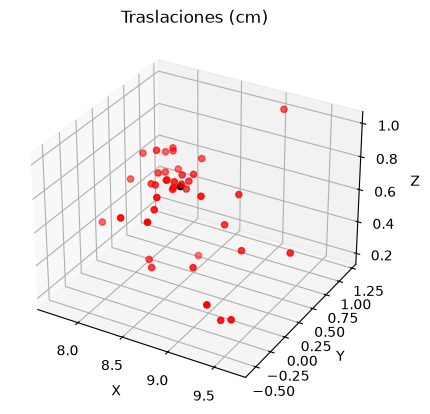

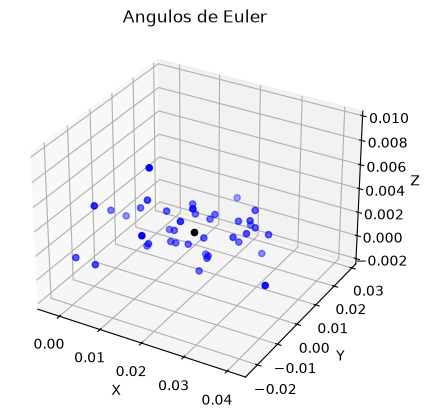

In [28]:
# Numero de imagenes
number_of_images=50
# Tiempo entre cada imagen
timer_time=1
# Configuracion del marcador ArUco
aruco_type='DICT_7X7_50'
aruco_id=0
square_size=145 # mm
# Tipo de calculo
calculation_type="median"
# Para mostrar resultados
show_results=True

stereo_vision.calibrate_stereo_system(number_of_images=number_of_images, timer_time=timer_time, max_number_of_failures=100, apiPreference=apiPreference, frame_width=frame_width, frame_height=frame_height, aruco_type=aruco_type, aruco_id=aruco_id, square_size=square_size, calculation_type=calculation_type, show_results=show_results)

## Guardar traslacion y rotacion de una camara con respecto a la otra

Los parametros de la calibracion estereo se guardan en el siguiente directorio:
**./stereo calibration parameters/<camera 1 name>|<camera 2 name>**

In [29]:
if stereo_vision.save_stereo_calibration_parameters():
    print("Se guardaron correctamente los parametros de calibracion del sistema estereo.")
else:
    print("Se tuvieron problemas al guardar los parametros de calibracion del sistema estereo :(.")

Se guardaron correctamente los parametros de calibracion del sistema estereo.


## Cargar traslacion y rotacion de una camara con respecto a la otra

In [16]:
if stereo_vision.load_stereo_calibration_parameters():
    print("Se cargaron correctamente los parametros de calibracion del sistema estereo.")
else:
    print("Se tuvieron problemas al cargar los parametros de calibracion del sistema estereo :(.")

Se cargaron correctamente los parametros de calibracion del sistema estereo.


In [17]:
T21=stereo_vision.T21
t21=stereo_vision.t21
print(T21)
print(t21)
print(f"Distancia entre las camara: {np.linalg.norm(t21) / 10} cm")

[[    0.99999  -0.0016653   0.0047913]
 [  0.0017473     0.99985   -0.017155]
 [  -0.004762    0.017163     0.99984]]
[[     85.172]
 [     2.5525]
 [     7.4856]]
Distancia entre las camara: 8.553850623624564 cm


## Mostrar traslacion y rotacion de una camara con respecto a la otra

In [32]:
fig=PlotCamera.plot_camera_coordinate_systems(stereo_vision.T21, stereo_vision.t21, title=f'Distancia aproximada: {(np.linalg.norm(stereo_vision.t21) / 10):.2f} cm')
fig.show()

# Calculo de puntos 3D con respecto al sistema de coordenadas de las camaras

In [38]:
# Captura de imagenes
distorted_image_bgr_1,distorted_image_bgr_2=stereo_vision.show_cameras(max_number_of_failures=100, apiPreference=apiPreference, frame_width=frame_width, frame_height=frame_height)
undistorted_image_bgr_1=PinholeCameraModel.undistorted_image_bgr(distorted_image_bgr_1, K_1, q_1)
undistorted_image_bgr_2=PinholeCameraModel.undistorted_image_bgr(distorted_image_bgr_2, K_1, q_1)

In [39]:
us_1=None
us_2=None

In [40]:
# Seleccion de puntos correspondientes
# Seleccionar un punto a la izquierda y otro a la derecha
# Presionar "q" para salir
us_1,us_2=manual_corresponding_points(undistorted_image_bgr_1, undistorted_image_bgr_2, us_1, us_2)
print(us_1.shape)
print(us_2.shape)

(2, 2)
(2, 2)


In [42]:
vc1s,vc2s,fs=PinholeCameraModel.estimate_cameras_3D_points(T21, t21, us_1, us_2, K_1, K_2)
print(np.linalg.norm(vc1s, axis=1) / 10) # mm a cm
print(np.linalg.norm(vc2s, axis=1) / 10) # mm a cm
print(fs)

[      48.41      47.069]
[     48.776       46.63]
[   0.022143   0.0026964]


In [43]:
fig=PlotCamera.plot_point_cloud(vcs=vc1s / 1000, title="", text="S.C. camara 1", subprefix="1") ## mm a mts
fig.show()

In [44]:
fig=PlotCamera.plot_point_cloud(vcs=vc2s / 1000, title="", text="S.C. camara 2", subprefix="2") ## mm a mts
fig.show()

# Secuencia de imagenes

## Crear secuencia de imagenes

In [72]:
# Numero de imagenes
number_of_images=100
# Tiempo entre cada imagen
timer_time=0.2
# Toma imagenes de forma automatica
stereo_vision.create_sequence(number_of_images=number_of_images, timer_time=timer_time, max_number_of_failures=100, apiPreference=apiPreference, frame_width=frame_width, frame_height=frame_height)

## Guardar secuencia de imagenes

In [73]:
if stereo_vision.save_sequence(sequence_name="sequence_08"):
    print("Se guardo la secuencia correctamente.")
else:
    print("Se tuvieron problemas al guardar la secuencia :(.")

Se guardo la secuencia correctamente.


## Cargar secuencia de imagenes

In [69]:
if stereo_vision.load_sequence(sequence_name="sequence_08"):
    print("Se cargo la secuencia correctamente.")
else:
    print("Se tuvieron problemas al cargar la secuencia :(.")

Se cargo la secuencia correctamente.


## Mostrar secuencia de imagenes

Tamaño de la secuencia: 100


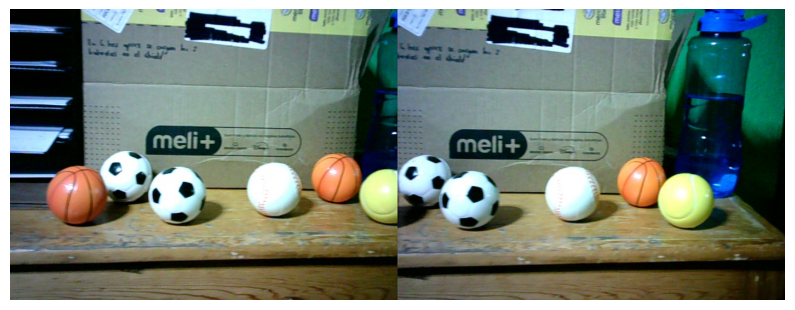

In [70]:
# Mostrar un par de imagenes de forma aleatoria
print(f"Tamaño de la secuencia: {len(stereo_vision.sequence)}")
index=np.random.randint(len(stereo_vision.sequence))
image_bgr_1,image_bgr_2=stereo_vision.sequence[index]
image_bgr = cv2.hconcat([image_bgr_1, image_bgr_2])
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(10, 5)) 
plt.imshow(image_rgb)
plt.axis('off')  
plt.show()

In [20]:
# Mostrar secuencia completa
stereo_vision.show_sequence(fps=15, replay=True)

# Conteo de objetos usando vision estereo

In [21]:
def get_candidates_on_image_1(coords_2, coords_list_1, F, T21, t21, K_1, K_2, d_2D_threshold):
    # Punto en la imagen 2
    u_2=bounding_box_midpoints([coords_2])[0]
    # Linea epipolar en la imagen 1 
    l_1=F @ np.hstack([u_2, 1])[:,None]
    l_1=l_1.flatten()
    # Calculamos distancias de la linea epipolar en la imagen 1 con los puntos en la imagen 1
    us_1=bounding_box_midpoints(coords_list_1)
    # Para guardar candidatos
    candidates=[]
    for i in range(us_1.shape[0]):
        # Punto en la imagen 1
        u_1=us_1[i]
        # Distancia en pixeles de la linea epipolar en la imagen 1 con el punto en la imagen 1
        d=np.abs(np.dot(l_1, np.hstack([u_1, 1]))) / np.linalg.norm(l_1[0:2])
        if d < d_2D_threshold:
            # Punto candidato
            # Calculamos el punto 3D con respecto a cada camara 
            vc1s,vc2s,fs=PinholeCameraModel.estimate_cameras_3D_points(T21, t21, u_1[None,:], u_2[None,:], K_1, K_2)
            vc1=vc1s[0]
            vc2=vc2s[0]
            f=fs[0]
            zc1=vc1[2]
            zc2=vc2[2]
            # Los puntos debes estar por delante de las camaras 
            # Esto automaticamente filtra todos los candidatos a la derecha
            if zc1 > 0 and zc2 > 0:
                # Punto candidato
                candidates.append((u_1, u_2, vc1, vc2, coords_list_1[i], coords_2, f, d, i))
    return candidates
    
def get_candidates_on_image_2(coords_1, coords_list_2, F, T21, t21, K_1, K_2, d_2D_threshold):
    # Punto en la imagen 1
    u_1=bounding_box_midpoints([coords_1])[0]
    # Linea epipolar en la imagen 2 
    l_2=F.T @ np.hstack([u_1, 1])[:,None]
    l_2=l_2.flatten()
    # Calculamos distancias de la linea epipolar en la imagen 2 con los puntos en la imagen 2
    us_2=bounding_box_midpoints(coords_list_2)
    # Para guardar candidatos
    candidates=[]
    for i in range(us_2.shape[0]):
        # Punto en la imagen 2
        u_2=us_2[i]
        # Distancia en pixeles de la linea epipolar en la imagen 2 con el punto en la imagen 2
        d=np.abs(np.dot(l_2, np.hstack([u_2, 1]))) / np.linalg.norm(l_2[0:2])
        if d < d_2D_threshold:
            # Punto candidato
            # Calculamos el punto 3D con respecto a cada camara 
            vc1s,vc2s,fs=PinholeCameraModel.estimate_cameras_3D_points(T21, t21, u_1[None,:], u_2[None,:], K_1, K_2)
            vc1=vc1s[0]
            vc2=vc2s[0]
            f=fs[0]
            zc1=vc1[2]
            zc2=vc2[2]
            # Los puntos debes estar por delante de las camaras 
            # Esto automaticamente filtra todos los candidatos a la derecha
            if zc1 > 0 and zc2 > 0:
                # Punto candidato
                candidates.append((u_1, u_2, vc1, vc2, coords_1, coords_list_2[i], f, d, i))
    return candidates

def object_correspondences(stereo_vision, coords_list_1, coords_list_2, d_2D_threshold, object_dimensions_hw, iou_threshold):
    # d_2D_threshold: Distancia entre la recta y el punto (en pixeles)
    # object_dimensions_hw: Dimensiones del objeto (en mm)
    ho,wo=object_dimensions_hw
    # Parametros de calibracion
    K_1,q_1,K_2,q_2=stereo_vision.get_calibration_parameters()
    # Parametros del sistema estereo
    T21=stereo_vision.T21
    t21=stereo_vision.t21
    # Matriz esencial y fundamental
    E,F=stereo_vision.get_essential_and_fundamental_matrix()
    # Creamos copia 
    cl_1=coords_list_1.copy()
    cl_2=coords_list_2.copy()
    # Para guardar informacion de los puntos correspondientes
    correspondences=[]
    for i in range(len(cl_1)):
        if len(cl_2) == 0:
            break
        candidates_2=get_candidates_on_image_2(cl_1[i], cl_2, F, T21, t21, K_1, K_2, d_2D_threshold)  
        if len(candidates_2) > 0:
            # No porque existan candidatos significa que entre ellos esta su correspondiente (puede o no estarlo)
            ious=[]
            for j in range(len(candidates_2)):
                vc1=candidates_2[j][2]
                # Esquina superior izquierda
                vc1_ul=vc1 + np.array([-wo / 2, -ho / 2, 0])
                # Esquina inferior derecha
                vc1_br=vc1 + np.array([wo / 2, ho / 2, 0])
                # Proyeccion de las esquinas del bounding box 
                us=PinholeCameraModel.projection_ideal_camera_model(
                    vws=np.vstack([vc1_ul, vc1_br]), 
                    K=K_1, 
                    Q=np.hstack([np.eye(3), np.zeros((3,1))])
                )
                # Formato: [x_min, y_min, x_max, y_max]
                box1=torch.tensor(np.array(cl_1[i])[None,:], dtype=torch.float)
                box2=torch.tensor(us.flatten(order='C')[None,:], dtype=torch.float)
                iou=ops.box_iou(box1, box2)
                # Va de 0 (ninguna superposición) a 1 (superposición perfecta).
                ious.append(iou.item())
            best_index=np.argmax(ious)
            if ious[best_index] >= iou_threshold:
                # Es correspondiente
                index_to_remove=candidates_2[best_index][8]
                correspondences.append([candidates_2[best_index][4], candidates_2[best_index][5]])
                cl_2.pop(index_to_remove)
    return correspondences

In [22]:
# Coordenadas del area candidata
def get_candidate_area_coords(coords, h, w, image_shape, pad_hw=(0,0)):
    # image_shape: (height,width)
    hi,wi=image_shape
    ph,pw=pad_hw
    # Coordenadas bounding box de referencia
    xrmin,yrmin,xrmax,yrmax=np.array(coords).astype(int)
    # Coordenadas del area candidata
    # Realizamos ajuste para que las coordenadas queden dentro de la imagen
    candidate_area_coords=[
        np.clip(xrmin - w - pw, 0, wi - 1), # xmin
        np.clip(yrmin - h - ph, 0, hi - 1), # ymin
        np.clip(xrmax + pw    , 0, wi - 1), # xmax
        np.clip(yrmax + h + ph, 0, hi - 1)  # ymax
    ]
    return candidate_area_coords

In [23]:
# Parche de una imagen
def get_patch(img_bgr, coords, pad_hw=(0,0)):
    # Dimensiones de la imagen
    hi,wi=img_bgr.shape[0:2]
    # Coordenadas bounding box
    xmin,ymin,xmax,ymax=np.array(coords).astype(int)
    ph,pw=pad_hw
    xmin=int(np.clip(xmin - pw, 0, wi - 1))
    ymin=int(np.clip(ymin - ph, 0, hi - 1))
    xmax=int(np.clip(xmax + pw, 0, wi - 1))
    ymax=int(np.clip(ymax + ph, 0, hi - 1))
    # Esquina superior izquierda
    p1=np.array([xmin, ymin]) 
    # Esquina inferior derecha
    p2=np.array([xmax, ymax]) 
    # Parche
    patch=img_bgr[ymin:ymax, xmin:xmax, :]
    return patch

In [24]:
# Devuelve verdadero si no es atipico, de lo contrario devuelve falso
# Toma en cuenta la distribucion normal
def nd_value_check(value, mean, std, n_std):
    return value >= mean - n_std * std and value <= mean + n_std * std

def filter_by_similarity(correspondences, similarity_factor):
    temp_correspondences=[]
    # Filtrado por similitud
    # No deben existir correspondencias muy similares
    indexes=np.arange(len(correspondences)).tolist()
    while len(indexes) > 0:
        i=indexes.pop(0)
        if len(indexes) == 0:
            temp_correspondences.append(correspondences[i])
            break
        coords1,coords2=correspondences[i]
        # Verificamos que no exista otra correspondencia muy similar
        # Una correspondencia contra todas las demas
        # Centro del bounding box en la imagen 1 y 2
        x1,y1=bounding_box_midpoints([coords1])[0]
        x2,y2=bounding_box_midpoints([coords2])[0]
        # Centro de los bounding boxes en la imagen 1 y 2
        ut1s=bounding_box_midpoints(list(map(lambda elem: elem[0], correspondences)))[indexes]
        ut2s=bounding_box_midpoints(list(map(lambda elem: elem[1], correspondences)))[indexes]
        norms1=np.linalg.norm(ut1s - np.tile(np.array([x1,y1]), (ut1s.shape[0], 1)), axis=1)
        norms2=np.linalg.norm(ut2s - np.tile(np.array([x2,y2]), (ut2s.shape[0], 1)), axis=1)
        index1=int(np.argmin(norms1))
        index2=int(np.argmin(norms2))
        if index1 == index2:
            # Ancho y alto del bounding box en la imagen 1 y 2
            w1,h1=coords1[2] - coords1[0],coords1[3] - coords1[1]
            w2,h2=coords2[2] - coords2[0],coords2[3] - coords2[1]
            # El umbral depende de las dimensiones del bounding box 
            d1_threshold=np.minimum(w1,h1) * similarity_factor
            d2_threshold=np.minimum(w2,h2) * similarity_factor
            # Validaciones por distancia
            if norms1[index1] < d1_threshold and norms2[index2] < d2_threshold:
                # Nos quedamos con una correspondencia de las dos (ya que son muy similares)
                # ¿Cual es mejor elegir?
                temp_correspondences.append(correspondences[i])
                indexes.pop(index1)
            else:
                # La correspondencia esta lo suficientemente lejos de las otras, por tanto, la agregamos
                temp_correspondences.append(correspondences[i])
        else:
            # Mantenemos
            temp_correspondences.append(correspondences[i])
    return temp_correspondences
    
def filter_correspondences(correspondences, output_threshold, input_threshold, image_shape, n_std, proportions_hw, similarity_factor, poblation):
    hi,wi=image_shape

    # Filtrado por zona
    temp_correspondences=[]
    for i,(coords1,coords2) in enumerate(correspondences):
        # Centro del bounding box en la imagen 1 y 2
        xc1,yc1=bounding_box_midpoints([coords1])[0]
        xc2,yc2=bounding_box_midpoints([coords2])[0]
        if xc1 > output_threshold:
            # Nos deshacemos de aquellas correspondencias que ya han salido para no tomarlas en cuenta de nuevo
            if xc1 > output_threshold and xc1 <= input_threshold:
                # Nos quedamos con aquellas que estan en la zona de tracking
                temp_correspondences.append(correspondences[i])

    if len(temp_correspondences) > 0:
        # Filtrado por tamaño 
        # Todas las correspondencias no deben exceder una tamaño de bounding box
        aux=[]
        ph,pw=proportions_hw
        for i,(coords1,coords2) in enumerate(temp_correspondences):
            # Ancho y alto del bounding box en la imagen 1 y 2
            w1,h1=coords1[2] - coords1[0],coords1[3] - coords1[1]
            w2,h2=coords2[2] - coords2[0],coords2[3] - coords2[1]
            if h1 <= hi * ph and h2 <= hi * ph and w1 <= wi * pw and w2 <= wi * pw:
                aux.append(temp_correspondences[i])
        temp_correspondences=aux.copy()
    
    if len(temp_correspondences) > 0:
        # Filtrado por tamaño
        # Todas las correspondencias deberian tener un tamaño de bounding box similar
        if len(poblation) > 0:
            aux=[]
            w_list=[]
            h_list=[]
            for coords1,coords2 in poblation:
                # Ancho y alto del bounding box en la imagen 1 y 2
                w1,h1=coords1[2] - coords1[0],coords1[3] - coords1[1]
                w2,h2=coords2[2] - coords2[0],coords2[3] - coords2[1]
                w_list.extend([w1,w2])
                h_list.extend([h1,h2])
            w_mean=np.mean(w_list)
            w_std=np.std(w_list)
            h_mean=np.mean(h_list)
            h_std=np.std(h_list)
            for i,(coords1,coords2) in enumerate(temp_correspondences):
                # Ancho y alto del bounding box en la imagen 1 y 2
                w1,h1=coords1[2] - coords1[0],coords1[3] - coords1[1]
                w2,h2=coords2[2] - coords2[0],coords2[3] - coords2[1]
                # Mantenemos si el bounding box es como los demas bounding boxes 
                if nd_value_check(w1, w_mean, w_std, n_std) and nd_value_check(w2, w_mean, w_std, n_std) and nd_value_check(h1, h_mean, h_std, n_std) and nd_value_check(h2, h_mean, h_std, n_std):
                    aux.append(temp_correspondences[i])
            temp_correspondences=aux.copy()
      
    if len(temp_correspondences) > 0:
        # Filtrado por similitud
        # No deben existir correspondencias muy similares
        temp_correspondences=filter_by_similarity(temp_correspondences, similarity_factor)

    return temp_correspondences

In [25]:
"""
Funcion de costo: 
    sum(abs(new_patch - old_patch))

Al final se tiene una funcion escalar de dos variables (x,y)

Podria agregarse a la funcion de costo una penalizacion dada la distancia que existe entre old_patch y new_patch
"""
# Trabaja con patches a color
def make_new_tracking(old_img_bgr, new_img_bgr, old_coords_list, space_hw, stride_hw, pad_hw):
    new_coords_list=[]
    h,w=space_hw
    sh,sw=stride_hw
    ph,pw=pad_hw
    for i, old_coords in enumerate(old_coords_list):
        # Coordenadas y dimensiones del bounding box de referencia (ancho y alto)
        xrmin, yrmin, xrmax, yrmax = np.array(old_coords).astype(int) 
        wr = xrmax - xrmin
        hr = yrmax - yrmin
        # Coordenadas del bounding box candidato 
        candidate_area_coords = get_candidate_area_coords(old_coords, h, w, image_shape=old_img_bgr.shape[0:2], pad_hw=pad_hw)
        xcmin, ycmin, xcmax, ycmax = candidate_area_coords
        # Kernel e imagen a utilizar (manteniendo los 3 canales de color normalizados)
        kernel = get_patch(old_img_bgr, old_coords, pad_hw) / 255.0
        img = get_patch(new_img_bgr, candidate_area_coords) / 255.0
        kernel_shape = kernel.shape  # Ahora es (Alto, Ancho, Canales)
        img_shape = img.shape
        # Tensores PyTorch: Reordenar de (Alto, Ancho, Canales) a (Canales, Alto, Ancho)
        kernel_tensor = torch.tensor(kernel, dtype=torch.float32).permute(2, 0, 1)
        img_tensor = torch.tensor(img, dtype=torch.float32).permute(2, 0, 1)
        # Adaptar las dimensiones a 4D (Batch, Channels, Height, Width) agregando el Batch
        kernel_tensor = kernel_tensor.unsqueeze(0)
        img_tensor = img_tensor.unsqueeze(0)
        # Extraer los parches usando unfold (solo se pasan las dimensiones espaciales Alto y Ancho al kernel_size)
        # Resultado: (Batch, Canales * kh * kw, Número_de_bloques)
        patches_tensor = torch.nn.functional.unfold(img_tensor, kernel_size=kernel_shape[:2], stride=stride_hw, padding=0)
        # Preparar el kernel y los parches para la resta
        # Aplanamos el kernel a un vector de N elementos y lo reestructuramos a (1, N, 1)
        # Usamos .reshape() en lugar de .view() porque .permute() hace que el tensor no sea contiguo
        kernel_plain_tensor = kernel_tensor.reshape(1, int(np.prod(kernel_shape)), 1)
        # Suma de las diferencias absolutas
        sum_abs_diff_tensor = torch.abs(patches_tensor - kernel_plain_tensor).sum(dim=1, keepdim=True) 
        # Calcular las dimensiones de la matriz de salida
        h_out = (img_shape[0] - kernel_shape[0]) // stride_hw[0] + 1
        w_out = (img_shape[1] - kernel_shape[1]) // stride_hw[1] + 1
        # Reestructurar el resultado de vuelta a una matriz 2D (usando reshape por seguridad)
        cost_tensor = sum_abs_diff_tensor.reshape(1, 1, h_out, w_out)
        cost_tensor = cost_tensor.squeeze(0).squeeze(0)
        # Transformar a Numpy
        cost = cost_tensor.numpy()
        # Elegimos la posicion con el menor costo
        best_cost_p = np.array(np.unravel_index(np.argmin(cost), cost.shape))
        # Nueva posicion
        new_coords = [
            xcmin + best_cost_p[1] * sw + pw,      # xmin
            ycmin + best_cost_p[0] * sh + ph,      # ymin
            xcmin + best_cost_p[1] * sw + pw + wr, # xmax
            ycmin + best_cost_p[0] * sh + ph + hr  # ymax
        ]
        new_coords_list.append(new_coords)
    return new_coords_list

In [26]:
def adjust_and_add_tracking(new_tracking, detected_correspondences, similarity_factor):
    temp_new_tracking=[]
    temp_detected_correspondences=detected_correspondences.copy()
    if len(temp_detected_correspondences) > 0:
        # Ajustar tracking en caso de ser necesario
        for i in range(len(new_tracking)):
            if len(temp_detected_correspondences) > 0:
                # Coordenadas del bounding box en la imagen 1 y 2
                coordst1,coordst2=new_tracking[i]
                # Ancho y alto del bounding box en la imagen 1 y 2
                wt1,ht1=coordst1[2] - coordst1[0],coordst1[3] - coordst1[1]
                wt2,ht2=coordst2[2] - coordst2[0],coordst2[3] - coordst2[1]
                # Centro del bounding box en la imagen 1 y 2
                ut1=bounding_box_midpoints([coordst1])[0]
                ut2=bounding_box_midpoints([coordst2])[0]
                # Centro de los bounding boxes en la imagen 1 y 2 de las correspondencias detectadas
                udcs1=bounding_box_midpoints(list(map(lambda elem: elem[0], temp_detected_correspondences)))
                udcs2=bounding_box_midpoints(list(map(lambda elem: elem[1], temp_detected_correspondences)))
                norms1=np.linalg.norm(udcs1 - np.tile(ut1, (udcs1.shape[0], 1)), axis=1)
                norms2=np.linalg.norm(udcs2 - np.tile(ut2, (udcs2.shape[0], 1)), axis=1)
                index1=int(np.argmin(norms1))
                index2=int(np.argmin(norms2))
                # El umbral depende de las dimensiones del bounding box de tracking
                d1_threshold=np.minimum(wt1, ht1) * similarity_factor
                d2_threshold=np.minimum(wt2, ht2) * similarity_factor
                if index1 == index2:
                    # Validaciones por distancia
                    if norms1[index1] < d1_threshold and norms2[index2] < d2_threshold:
                        # Encontramos una correspondencia detectada candidata
                        # Nos quedamos con la correspondencia detectada
                        temp_new_tracking.append(temp_detected_correspondences[index1].copy())
                        temp_detected_correspondences.pop(index1)
                    else:
                        # Mantenemos el tracking
                        temp_new_tracking.append(new_tracking[i].copy())
                else:
                    # Mantenemos el tracking
                    temp_new_tracking.append(new_tracking[i].copy())
            else:
                # Mantenemos el tracking
                temp_new_tracking.append(new_tracking[i].copy())  
        # Las correspondencias detectadas restantes las agregamos al tracking
        temp_new_tracking.extend(temp_detected_correspondences)
        return temp_new_tracking
    else:
        return new_tracking.copy()

In [27]:
def check_tracking(new_img_bgr_1, new_img_bgr_2, new_tracking, output_threshold):
    temp_new_tracking=[]
    out=0
    correspondence_patches=[]    
    tracking_out=[]
    for i in range(len(new_tracking)):
        coords1,coords2=new_tracking[i]
        # Centro del bounding box en la imagen 1 y 2
        xtc1,ytc1=bounding_box_midpoints([coords1])[0]
        xtc2,ytc2=bounding_box_midpoints([coords2])[0]
        if xtc1 <= output_threshold:
            # Nos deshacemos de los que se encuentran en la zona de salida
            out+=1
            correspondence_patches.append([
                get_patch(new_img_bgr_1, new_tracking[i][0]),
                get_patch(new_img_bgr_2, new_tracking[i][1])
            ])
            tracking_out.append([
                new_tracking[i][0],
                new_tracking[i][1]
            ])
            print("Objeto contado !!!") 
        else:
            temp_new_tracking.append(new_tracking[i].copy())    
    return temp_new_tracking,out,correspondence_patches,tracking_out

In [28]:
def show_sequence_correspondences(
    stereo_vision, 
    fps, 
    output_threshold, 
    input_threshold, 
    d_2D_threshold, 
    space_hw, 
    stride_hw, 
    pad_hw,
    n_std,
    proportions_hw,
    object_dimensions_hw,
    iou_threshold,
    similarity_factor,
    poblation_limit
):
    # Parametros de calibracion
    K_1,q_1,K_2,q_2=stereo_vision.get_calibration_parameters()
    # Matriz esencial y fundamental
    E,F=stereo_vision.get_essential_and_fundamental_matrix()
    # Dimensiones de las imagenes (h,w)
    image_shape=stereo_vision.sequence[0][0].shape[0:2]
    hi,wi=image_shape
    # Funcion para graficar las lineas epipolares
    y=lambda l,x: -(l[0] * x + l[2]) / l[1]
    # Delay en milisegundos
    delay = int(1000 / fps) 
    start=0
    end=len(stereo_vision.sequence)

    old_img_bgr_1=None
    new_img_bgr_1=None
    old_img_bgr_2=None
    new_img_bgr_2=None
    old_tracking=[]
    new_tracking=[]
    count=0
    patches=[]
    poblation=[]
    images=[]
    for t in range(start,end):
        distorted_image_bgr_1,distorted_image_bgr_2=stereo_vision.sequence[t]
        # Imagenes sin distorsion
        image_bgr_1=PinholeCameraModel.undistorted_image_bgr(distorted_image_bgr_1, K_1, q_1)
        image_bgr_2=PinholeCameraModel.undistorted_image_bgr(distorted_image_bgr_2, K_1, q_1)

        # Guardamos la nueva y antigua imagen de cada camara
        if t == 0:
            old_img_bgr_1=None
            new_img_bgr_1=image_bgr_1.copy()
            old_img_bgr_2=None
            new_img_bgr_2=image_bgr_2.copy()
        else:
            old_img_bgr_1=new_img_bgr_1.copy()
            new_img_bgr_1=image_bgr_1.copy()
            old_img_bgr_2=new_img_bgr_2.copy()
            new_img_bgr_2=image_bgr_2.copy()

        # Coordenadas de los bounding boxes
        coords_list_1=object_detection.detect_objects(image_bgr_1)
        coords_list_2=object_detection.detect_objects(image_bgr_2)
        
        # Calculo de las correspondencias
        detected_correspondences=object_correspondences(
            stereo_vision, 
            coords_list_1, 
            coords_list_2, 
            d_2D_threshold,
            object_dimensions_hw,
            iou_threshold
        )

        # Nos quedamos solo con correspondencias que estan en zona de tracking
        detected_correspondences=filter_correspondences(
            detected_correspondences, 
            output_threshold, 
            input_threshold,
            image_shape,
            n_std,
            proportions_hw,
            similarity_factor,
            poblation
        )

        # Las asignamos para hacerles tracking a las correspondencias
        if len(detected_correspondences) > 0 and len(old_tracking) == 0:
            old_tracking=detected_correspondences
        
        # Hacemos tracking
        if (old_img_bgr_1 is not None and new_img_bgr_1 is not None) and (old_img_bgr_2 is not None and new_img_bgr_2 is not None):
            # Calculamos una nueva posicion para el tracking
            coords_list_1=make_new_tracking(
                old_img_bgr_1, 
                new_img_bgr_1, 
                list(map(lambda elem: elem[0], old_tracking)), 
                space_hw,
                stride_hw, 
                pad_hw
            )
            coords_list_2=make_new_tracking(
                old_img_bgr_2, 
                new_img_bgr_2, 
                list(map(lambda elem: elem[1], old_tracking)), 
                space_hw,
                stride_hw, 
                pad_hw
            )
            new_tracking=[list(par) for par in zip(coords_list_1, coords_list_2)]

            # Ajustamos correspondencias a las que se les hace tracking y agregamos correspondencias nuevas al tracking
            new_tracking=adjust_and_add_tracking(
                new_tracking, 
                detected_correspondences,
                similarity_factor
            )

            # Filtramos para no tener mas de un tracking similar
            new_tracking=filter_by_similarity(new_tracking, similarity_factor)

            # Verificamos el tracking
            new_tracking,out,correspondence_patches,tracking_out=check_tracking(
                new_img_bgr_1, 
                new_img_bgr_2,
                new_tracking, 
                output_threshold
            )

            # Conteo
            count+=out
            patches.extend(correspondence_patches)
            poblation.extend(tracking_out)
            while len(poblation) > poblation_limit:
                poblation.pop(0)
            
            # Actualizar
            old_tracking=new_tracking   
            
        # Dibujo de las correspondencias
        for coords1,coords2 in new_tracking:
            ut1=bounding_box_midpoints([coords1])[0]
            ut2=bounding_box_midpoints([coords2])[0]
            color=np.random.randint(0,255,3).tolist()
            # Dibujar bounding boxes
            image_bgr_1=object_detection.draw_bounding_boxes(image_bgr_1, [coords1])
            image_bgr_2=object_detection.draw_bounding_boxes(image_bgr_2, [coords2])
            # Dibujar puntos 
            image_bgr_1=cv2.circle(image_bgr_1, ut1.astype(int), radius=10, color=color, thickness=-1)
            image_bgr_2=cv2.circle(image_bgr_2, ut2.astype(int), radius=10, color=color, thickness=-1)
            # Dibujo de la linea epipolar
            # Linea epipolar
            l2=F.T @ np.hstack([ut1, 1])[:,None]
            l2=l2.flatten()
            # Linea epipolar en la segunda imagen
            image_bgr_2=cv2.line(image_bgr_2, (0, int(y(l2, 0))), (wi, int(y(l2, wi))), color, 2)

        image_bgr=cv2.hconcat([image_bgr_1, image_bgr_2])
        image_bgr=cv2.putText(
            image_bgr, 
            f'{t}/{end - 1}', 
            (10, 30), 
            cv2.FONT_HERSHEY_SIMPLEX, 
            1, 
            (0, 0, 255), 
            2, 
            cv2.LINE_AA
        )
        images.append(image_bgr)
        cv2.imshow(f"Video (presionar 'q' para salir)", image_bgr)    
        if cv2.waitKey(delay) & 0xFF == ord('q'):
            break
    cv2.destroyAllWindows()
    return count,patches,images

In [29]:
object_detection=ObjectDetection()

In [71]:
# Dimensiones de las imagenes (h,w)
image_shape=stereo_vision.sequence[0][0].shape[0:2]
hi,wi=image_shape

count,patches,images=show_sequence_correspondences(
    stereo_vision, 
    fps=30, 
    output_threshold=wi * 0.5,     # Zona de salida
    input_threshold=wi - wi * 0.2, # Zona de entrada
    d_2D_threshold=5,              # Distancia en pixeles de la linea epipolar en la imagen 2 con el punto en la imagen 2
    space_hw=(50,50),              # Espacio en alto y ancho sobre el bounding box de referencia para crear un bounding box mas grande sobre el, el cual se utiliza para hacer tracking
    stride_hw=(5,5),               # Funcionamiento similar al de las convoluciones, el cual se utiliza para hacer tracking
    pad_hw=(10,10),                # Funcionamiento similar al de las convoluciones, el cual se utiliza para hacer tracking
    n_std=3,                       # Numero de desviaciones estandar a considerar para filtrar por tamaño de bounding box
    proportions_hw=(0.5,0.5),      # Proporciones de alto y ancho de la imagen que no deben superar los bounding boxes
    object_dimensions_hw=(63,63),  # Dimensiones del objeto de interes (en mm)
    iou_threshold=0.7,             # Umbral que permite tomar una decision ante bounding boxes candidatos
    similarity_factor=0.5,         # Factor de distancia que permite identificar bounding boxes similares
    poblation_limit=100,           # Tamaño de la memoria para guardar objetos una vez sean contados 
)

Objeto contado !!!
Objeto contado !!!
Objeto contado !!!
Objeto contado !!!
Objeto contado !!!
Objeto contado !!!
Objeto contado !!!
Objeto contado !!!
Objeto contado !!!
Objeto contado !!!
Objeto contado !!!
Objeto contado !!!


Count: 12


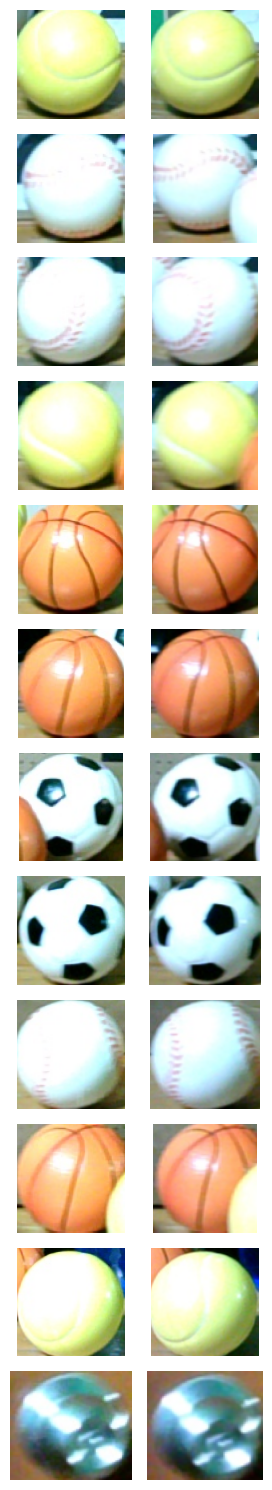

In [72]:
print(f"Count: {count}")
fig,axes=plt.subplots(len(patches), 2, figsize=(3, 15))
for i in range(len(patches)):
    axes[i,0].imshow(cv2.cvtColor(patches[i][0], cv2.COLOR_BGR2RGB))
    axes[i,0].axis('off')  
    axes[i,1].imshow(cv2.cvtColor(patches[i][1], cv2.COLOR_BGR2RGB))
    axes[i,1].axis('off')  
plt.tight_layout()
# Guardar resultados
sequence_name="sequence_08"
plt.savefig(f"{stereo_vision.path_sequences}/{sequence_name}/results.png", dpi=300, bbox_inches="tight")
plt.show()

In [73]:
# Dimensiones de la imagen
h, w, d = images[0].shape
frame_size = (w, h)
# Configurar el VideoWriter
# Nombre del archivo de salida, códec FOURCC, FPS y tamaño
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
fps = 5.0
out = cv2.VideoWriter(f"{stereo_vision.path_sequences}/{sequence_name}/results.mp4", fourcc, fps, frame_size)
# Recorrer la secuencia de imágenes y escribirlas en el video
for image in images:
    out.write(image)
# Liberar el objeto VideoWriter
out.release()
print("¡Video creado con éxito!")

¡Video creado con éxito!


# Comprender resultados lineas epipolares para el metodo de correspondencias

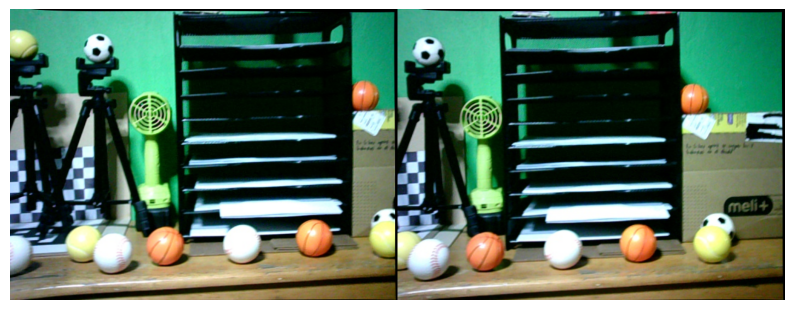

In [111]:
# Matriz esencial y fundamental
E,F=stereo_vision.get_essential_and_fundamental_matrix()
# Dimensiones de las imagenes (h,w)
image_shape=stereo_vision.sequence[0][0].shape[0:2]
hi,wi=image_shape
# Parametros de calibracion
K_1,q_1,K_2,q_2=stereo_vision.get_calibration_parameters()
# Imagenes sin distorsion
t=50
image_bgr_1=PinholeCameraModel.undistorted_image_bgr(stereo_vision.sequence[t][0], K_1, q_1)
image_bgr_2=PinholeCameraModel.undistorted_image_bgr(stereo_vision.sequence[t][1], K_1, q_1)

fig,ax=plt.subplots(1, 1, figsize=(10, 5))
ax.imshow(cv2.cvtColor(cv2.hconcat([
    image_bgr_1,
    image_bgr_2
]), cv2.COLOR_BGR2RGB))
ax.axis('off')  
plt.show()

In [112]:
def temp_click_event_point(event, x, y, flags, params, img, original_img, points, numerate):
    circle_radius=10
    if event == cv2.EVENT_LBUTTONDOWN:
        # Agregamos
        color=(0,0,255) # Rojo (por defecto)
        count=len(points) + 1 
        if numerate:
            cv2.putText(img, f'{count}', (int(x), int(y)), cv2.FONT_HERSHEY_SIMPLEX, 1.0, color, 2, cv2.LINE_AA)
        cv2.circle(img, center=(int(x), int(y)), radius=5, color=color, thickness=-1)
        cv2.imshow('image', img)
        points.append((x,y)) 
    if event == cv2.EVENT_MOUSEMOVE:
        # Mostramos circulo
        img_copy=img.copy()
        cv2.circle(img_copy, center=(int(x), int(y)), radius=circle_radius, color=(0,0,0), thickness=2)
        cv2.imshow('image', img_copy)

def temp_points_from_image(img_bgr, numerate=True):
    img=img_bgr.copy()
    original_img=img_bgr.copy()
    h,w,=img.shape[0:2]
    points=[]  
    cv2.namedWindow("image", cv2.WINDOW_GUI_NORMAL)
    cv2.setWindowProperty("image", cv2.WND_PROP_FULLSCREEN, cv2.WINDOW_FULLSCREEN)
    cv2.imshow('image', img)
    cv2.setMouseCallback('image', lambda event, x, y, flags, params: temp_click_event_point(event, x, y, flags, params, img, original_img, points, numerate))
    while True:
        k = cv2.waitKey(1) 
        if k == ord('q'): 
            break
    cv2.destroyAllWindows()
    cv2.waitKey(1) 
    return np.array(points)

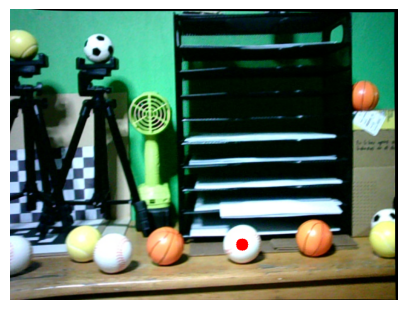

In [113]:
u_1=temp_points_from_image(image_bgr_1, numerate=True)[0]
image_bgr_1=cv2.circle(image_bgr_1, u_1.astype(int), radius=10, color=(0,0,255), thickness=-1)
    
fig,ax=plt.subplots(1, 1, figsize=(5, 5))
ax.imshow(cv2.cvtColor(image_bgr_1, cv2.COLOR_BGR2RGB))
ax.axis('off')  
plt.show()

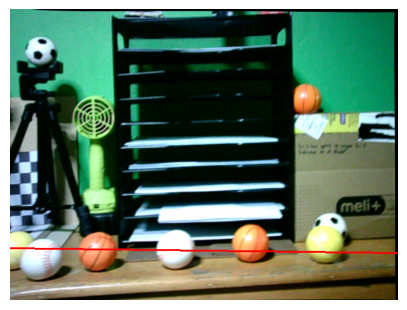

In [114]:
# Funcion para graficar las lineas epipolares
y=lambda l,x: -(l[0] * x + l[2]) / l[1]
# Dibujo de la linea epipolar
# Linea epipolar
l2=F.T @ np.hstack([u_1, 1])[:,None]
l2=l2.flatten()
# Linea epipolar en la segunda imagen
image_bgr_2=cv2.line(image_bgr_2, (0, int(y(l2, 0))), (wi, int(y(l2, wi))), (0,0,255), 2)

fig,ax=plt.subplots(1, 1, figsize=(5, 5))
ax.imshow(cv2.cvtColor(image_bgr_2, cv2.COLOR_BGR2RGB))
ax.axis('off')  
plt.show()

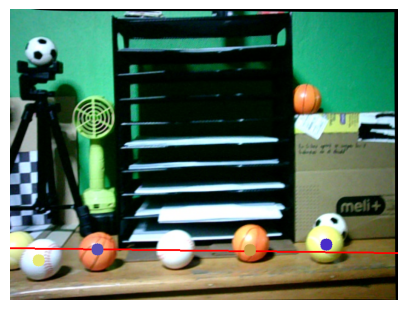

In [115]:
# Elegir puntos cercas de la linea epipolar
# Todos estos puntos son candidatos
us_2=temp_points_from_image(image_bgr_2, numerate=True)
colors=[]
for i in range(us_2.shape[0]):
    u_2=us_2[i]
    color=np.random.randint(0,255,3).tolist()
    colors.append(color)
    image_bgr_2=cv2.circle(image_bgr_2, u_2.astype(int), radius=10, color=color, thickness=-1)
    
fig,ax=plt.subplots(1, 1, figsize=(5, 5))
ax.imshow(cv2.cvtColor(image_bgr_2, cv2.COLOR_BGR2RGB))
ax.axis('off')  
plt.show()

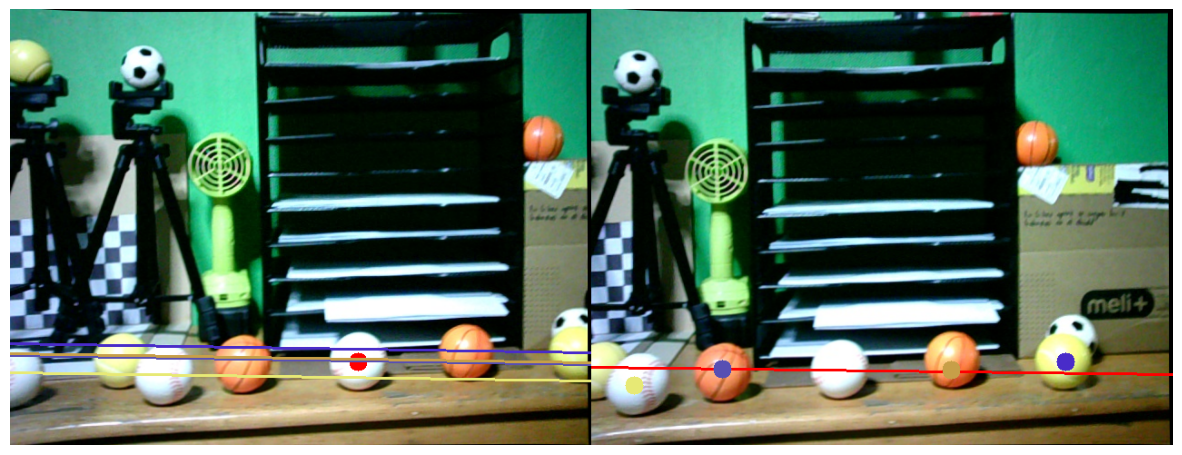

In [116]:
# Funcion para graficar las lineas epipolares
y=lambda l,x: -(l[0] * x + l[2]) / l[1]
for i in range(us_2.shape[0]):
    u_2=us_2[i]
    # Dibujo de la linea epipolar
    # Linea epipolar
    l1=F @ np.hstack([u_2, 1])[:,None]
    l1=l1.flatten()
    # Linea epipolar en la segunda imagen
    image_bgr_1=cv2.line(image_bgr_1, (0, int(y(l1, 0))), (wi, int(y(l1, wi))), colors[i], 2)

fig,ax=plt.subplots(1, 1, figsize=(15, 10))
ax.imshow(cv2.cvtColor(cv2.hconcat([
    image_bgr_1,
    image_bgr_2
]), cv2.COLOR_BGR2RGB))
ax.axis('off')  
plt.show()

NOTAS:
- Realmente no estaba ayudando lo que habia implementado en el metodo de correspondencias
- La relacion inversa tampoco ayuda
- El candidado con la distancia mas corta es el que al final se elije
- Todas las rectas en la imagen 1 son paralelas
- ¿Como realmente identificar a su correspondiente en la imagen 2 si existen muchos candidatos?
    - De alguna manera tenemos que usar la informacion visual
    - Esta claro que su correspondiente esta hacia la izquierda dado el movimiento de las camaras

## Caso donde SI esta su correspondiente

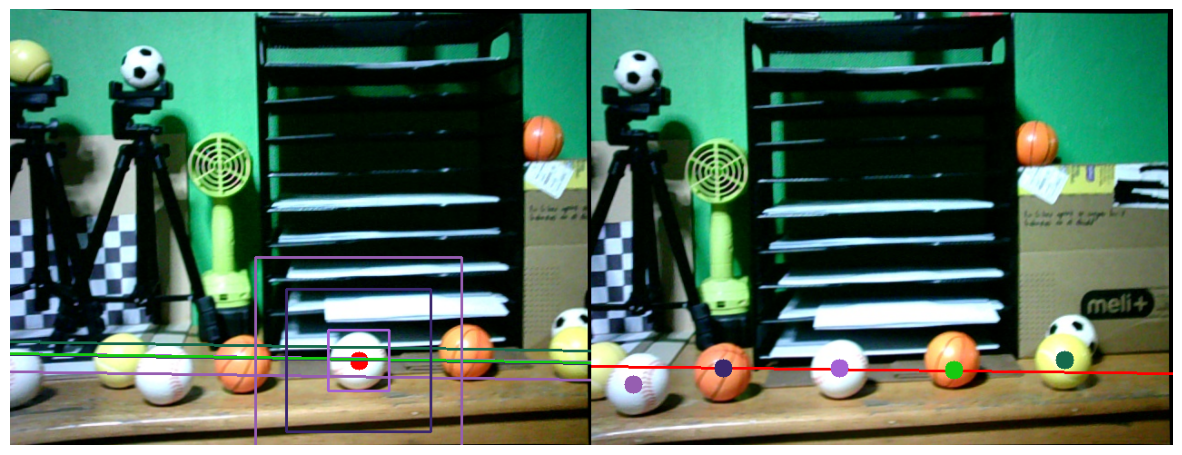

In [74]:
# Dimensiones del objeto en mm
ho=63
wo=63

img1=image_bgr_1.copy()
img2=image_bgr_2.copy()

for i in range(us_2.shape[0]):
    u_2=us_2[i]
    # Calculamos el punto 3D con respecto a cada camara para cada candidato
    vc1s,vc2s,fs=PinholeCameraModel.estimate_cameras_3D_points(T21, t21, u_1[None,:], u_2[None,:], K_1, K_2)
    vc1=vc1s[0]
    vc2=vc2s[0]
    f=fs[0]
    zc1=vc1[2]
    zc2=vc2[2]
    # Los puntos debes estar por delante de las camaras 
    if zc1 > 0 and zc2 > 0:
        # print(np.linalg.norm(vc1))
                
        # Esquina superior izquierda
        vc1_ul=vc1 + np.array([-wo / 2, -ho / 2, 0])
        # Esquina inferior derecha
        vc1_br=vc1 + np.array([wo / 2, ho / 2, 0])
        
        us=PinholeCameraModel.projection_ideal_camera_model(
            vws=np.vstack([vc1_ul, vc1_br]), 
            K=K_1, 
            Q=np.hstack([np.eye(3), np.zeros((3,1))])
        )
    
        xmin,ymin,xmax,ymax=us.flatten(order='C').astype(int)
        p1 = np.array([xmin, ymin]) # Esquina superior izquierda
        p2 = np.array([xmax, ymax]) # Esquina inferior derecha
        # Dibujar el rectangulo del objeto
        img1=cv2.rectangle(img1, p1, p2, colors[i], 2)
        # print(p1,p2)

fig,ax=plt.subplots(1, 1, figsize=(15, 10))
ax.imshow(cv2.cvtColor(cv2.hconcat([
    img1,
    img2
]), cv2.COLOR_BGR2RGB))
ax.axis('off')  
plt.show()

NOTAS:
- Podemos observar que se filtran todos los candidatos a la derecha del objeto de referencia
- De los candidatos, es posible observar que dos de ellos estan practicamente sobre la linea epipolar en la imagen 2, sin embargo, sus bounding boxes en la imagen 1 son diferentes, por lo que podemos concluir lo siguiente:
    - El correspondiente es aquel con el bounding box mas pequeño (el que tenga el area mas pequeña)
    - El correspondiente es aquel que su bounding box coincida con el bounding box de la imagen 1

## Caso donde NO esta su correspondiente

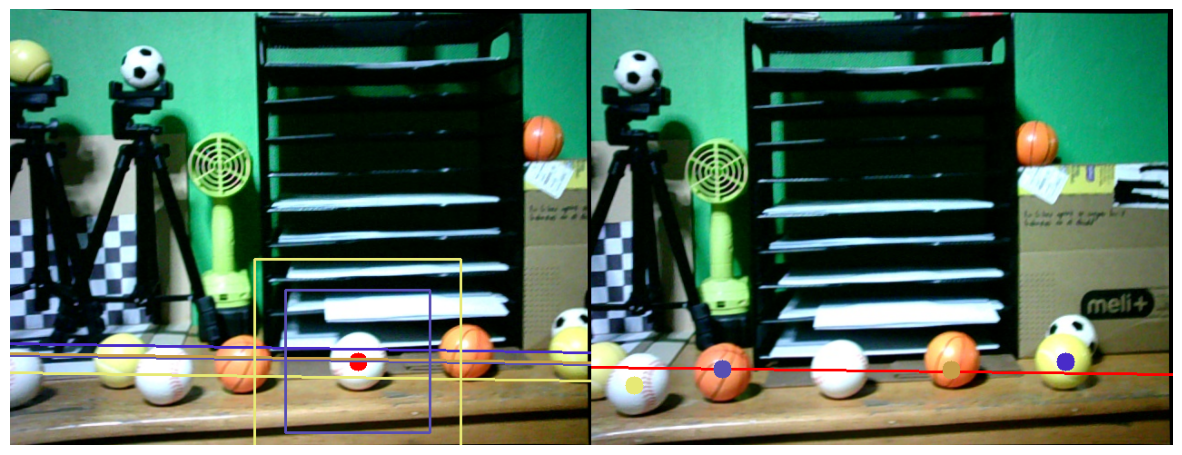

In [117]:
# Dimensiones del objeto en mm
ho=63
wo=63

img1=image_bgr_1.copy()
img2=image_bgr_2.copy()

for i in range(us_2.shape[0]):
    u_2=us_2[i]
    # Calculamos el punto 3D con respecto a cada camara para cada candidato
    vc1s,vc2s,fs=PinholeCameraModel.estimate_cameras_3D_points(T21, t21, u_1[None,:], u_2[None,:], K_1, K_2)
    vc1=vc1s[0]
    vc2=vc2s[0]
    f=fs[0]
    zc1=vc1[2]
    zc2=vc2[2]
    # Los puntos debes estar por delante de las camaras 
    if zc1 > 0 and zc2 > 0:
        # print(np.linalg.norm(vc1))
                
        # Esquina superior izquierda
        vc1_ul=vc1 + np.array([-wo / 2, -ho / 2, 0])
        # Esquina inferior derecha
        vc1_br=vc1 + np.array([wo / 2, ho / 2, 0])
        
        us=PinholeCameraModel.projection_ideal_camera_model(
            vws=np.vstack([vc1_ul, vc1_br]), 
            K=K_1, 
            Q=np.hstack([np.eye(3), np.zeros((3,1))])
        )
    
        xmin,ymin,xmax,ymax=us.flatten(order='C').astype(int)
        p1 = np.array([xmin, ymin]) # Esquina superior izquierda
        p2 = np.array([xmax, ymax]) # Esquina inferior derecha
        # Dibujar el rectangulo del objeto
        img1=cv2.rectangle(img1, p1, p2, colors[i], 2)
        # print(p1,p2)

fig,ax=plt.subplots(1, 1, figsize=(15, 10))
ax.imshow(cv2.cvtColor(cv2.hconcat([
    img1,
    img2
]), cv2.COLOR_BGR2RGB))
ax.axis('off')  
plt.show()

NOTAS:
- No basta con elegir aquel bounding box con el area minima
- Lo que realmente debemos comparar es que tan parecido es el boundig box proyectado con el de referencia
- En este caso podriamos concluir que no se detecto su correspondencia en la imagen 2
- Necesitamos definir una medida de similitud entre bounding boxes
    - IoU (Intersection over Union)
        - Concepto: Mide el área de superposición entre dos cajas dividida por el área de su unión
        - Rango: Va de 0 (ninguna superposición) a 1 (superposición perfecta)
        - Formula: $\frac{\text{Area de la inserseccion}}{\text{Area de la union}}$

In [119]:
import torch
import torchvision.ops as ops

# Formato: [x_min, y_min, x_max, y_max]
box1 = torch.tensor([[100, 100, 200, 200]], dtype=torch.float)
box2 = torch.tensor([[150, 150, 250, 250]], dtype=torch.float)

# Devuelve una matriz con los IoU calculados
# Es conmutativo (no importa el orden de los bounding boxes)
iou = ops.box_iou(box1, box2)
print(iou.item())  # Ejemplo de salida: 0.1428

0.1428571492433548
